# GridPulse

**Has large-load growth from AI data centers made Texas electricity harder to predict?**

Arjun Abbimutt Nagendra Kumar (EID: aa229243)
Introduction to Machine Learning, Prof. Varun Rai, Fall 2026

---

### The question:

Texas electricity demand used to follow the weather. Hot afternoon, high load. Cool night, low load.
Since about 2022 a large amount of new always-on demand (mostly data centers and crypto) has arrived.
It runs flat day and night and ignores the weather. Did that make Texas load harder to predict from
public data?

### Research questions (from the proposal)

1. How accurately can ERCOT demand and net load be predicted 24 hours ahead from public weather,
   calendar and lagged load? **Sections 8 and 9**
2. Can grid stress hours be flagged 24 hours ahead? **Section 10**
3. Has predictability changed as the load mix shifted? **Sections 8c to 8k and 11**

### Hypotheses

| # | Hypothesis | Tested in |
|---|---|---|
| H1 | Always-on load raises the overnight floor faster than the afternoon peak | 3, 8k, 11 |
| H2 | This makes Texas load harder to predict from public data | 8c to 8f, 9 |
| H3 | Load is becoming less weather-driven, relative to its size | 8f to 8k |
| H4 | Stress hours can be flagged 24 hours ahead better than "same as yesterday" | 10 |

### How to run it

Run every section top to bottom. Raw data is cached in Google Drive, so after the first run nothing
re-downloads. Sections 1 to 8 take about three minutes; 9 and 10 take about twelve more on free Colab. Every result is followed by a chart and a short note on how to read it.

### Sections

| # | Section | What it produces |
|---|---------|------------------|
| 1 | Setup | Mounts Drive, makes folders |
| 2 | ERCOT operating data | `ercot_hourly_2019_2026.parquet` |
| 3 | Preliminary analysis | The load-flattening result |
| 4 | Weather data | Eight zone CSVs |
| 5 | Zone weights | Demand weights per zone and zone growth |
| 6 | Merge and alignment | `ercot_merged.parquet` |
| 7 | Feature engineering | `ercot_features.parquet` |
| 8 | Baselines and the predictability question | Prediction error over time, weather response tests |
| 9 | Regularisation, bias-variance, non-linear models | Which models and features work, and why |
| 10 | Stress classification | Can stress hours be flagged a day ahead |
| 11 | Clustering daily load shapes | Are daily shapes changing |
| 12 | Conclusions | Answers to the questions and hypotheses |

## Results log (full run, Oct 30, 2026)

**F1. Load shape flattened.** Daily min-to-max ratio 0.696 (2019) to 0.728 (2025). Average daily
minimum up 41.2%, average daily peak up 33.9% (2019 to 2026).

**F2. Growth is geographic.** Far West share of ERCOT demand 7.68% to 13.46%, North 2.24% to 3.44%
(2019 to 2025). Houston and Dallas fell in share despite absolute growth.

**F3. Demand did not get harder to predict.** Ridge, 24 hours ahead: 3.2, 3.5, 3.4, 3.0, 2.8% error
across rolling-origin folds. The latest fold is the best. ERCOT's own forecast stays about one point
better, which is the gap between public and private data.

**F4. Net load got harder, by arithmetic.** 10.6% to 12.4% error. The solar fleet more than tripled
(2,793 to 9,253 MW average), so solar error in MW doubled (1,569 to 3,164 MW) against a flat net-load
base, even though solar error in percent improved (56% to 34%).

**F5. Texas load is less weather-driven per MW.** Each degree of heat now adds 4.6% of the no-weather
level (2025) vs 5.8% (2019). Early vs late era difference -0.70 points, 95% weekly block bootstrap CI
[-0.96, -0.45]. The level grew 31% while the cooling response in MW grew 4%.

**F6. The change is concentrated in Far West Texas.** Weather explains 65% of Far West demand in 2019
and 21% in 2025; its cooling response fell from 0.95% to 0.19% per C. North is weakening too. Houston,
Dallas, Austin and Corpus Christi stay weather-shaped (R2 0.82 to 0.92 in every year).

**F7. The missing piece is the rising floor.** A weather-only model's error doubles across folds (6.9%
to 13.5%). Adding one feature, the 90-day minimum load, brings the latest fold back to 4.4%. Training a
weather-only model on more history makes it worse (4.3% with one year, 13.5% with all years): the old
weather-to-load relationship has gone stale.

**F8. Linear beats trees on this problem.** Ridge 3.18%, gradient boosting 3.32%, random forest 4.21%.
On the hottest 5% of hours, Ridge 1,567 MW vs random forest 5,240 MW: trees cannot predict above the
highest load they have seen (91,075 MW test peak vs 85,544 MW training peak).

**F9. Stress hours: persistence is hard to beat.** 5.9% of hours are net-load stress hours, 75% of
them in July to September. "Stressed yesterday at this hour" scores AUC-PR 0.746; the best model (RBF
SVM) 0.767. Models catch more stress hours only at the cost of more false alarms.

**F10. Unsupervised check agrees.** Share of summer days with a flatter-than-normal shape rose from 8%
(2019) to 22% (2025).

**Validation.** Random k-fold understates error by 15.5% vs rolling-origin. Hourly errors are strongly
autocorrelated (Durbin-Watson 0.11), so naive bootstrap standard errors are 5.9x too narrow; all
confidence intervals use weekly blocks.

**Dropped.** Capacity proxies (they leaked growth information). Fold 2 "Winter Storm Heather" anomaly
(a proxy artefact).

### AI use declaration (draft, edit in your own words before submission)

I used Claude (Anthropic) as an assistant throughout this project: scoping the question, finding
public data sources, drafting and debugging code and reviewing results for leakage and errors. I ran
every cell myself, checked each output against what I expected and made the decisions about which
analyses to keep, drop or redo. I can explain every step of the code and every result in this
notebook.

---
# 1. Setup

Finds the project folders and prints the library versions.

**Where the data comes from.** The notebook runs in two places. In Colab it mounts Google Drive. Anywhere
else it uses the folders inside the repo. Either way, every loading cell looks in `data/snapshot/` first (the
frozen inputs behind the reference run), then in the raw cache, and only downloads if both are missing.

**Date window.** `START_UTC` and `END_UTC` cut every input to the same window as the reference run, so a
fresh download that holds later hours still gives the same rows.

**One trap to know about (Colab).** If Drive is not mounted, `os.makedirs` will happily create a normal
local folder at the same path. It looks identical, your files write to it, and they vanish on the
next disconnect. In Colab, every cell below that writes a file starts with a `assert os.path.ismount(...)`
so this fails loudly instead of silently.

In [1]:
import os, sys, platform
from importlib.metadata import version

IN_COLAB = "google.colab" in sys.modules

# the window of the reference run (UTC, hour ending); every loading cell filters to it
START_UTC = "2019-01-01 00:00"
END_UTC   = "2026-09-19 05:00"

if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyarrow", "openpyxl", "holidays"], check=True)
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = "/content/drive/MyDrive/gridpulse"
    assert os.path.ismount("/content/drive"), "Drive not mounted"
    WX = f"{ROOT}/data/weather"
else:
    # repo root = first folder above the working directory that holds requirements.txt
    ROOT = os.getcwd()
    while not os.path.exists(f"{ROOT}/requirements.txt") and os.path.dirname(ROOT) != ROOT:
        ROOT = os.path.dirname(ROOT)
    WX = f"{ROOT}/data/raw/weather"
RAW  = f"{ROOT}/data/raw"
SNAP = f"{ROOT}/data/snapshot"
OUT  = f"{ROOT}/data/processed"

for p in (RAW, WX, OUT):
    os.makedirs(p, exist_ok=True)

print("environment :", "Colab" if IN_COLAB else "local")
print("project root:", ROOT)
print("snapshot    :", "found" if os.path.isdir(SNAP) else "not found (will use the raw cache or download)")
print("raw         :", len(os.listdir(RAW)), "files")
print("weather     :", len(os.listdir(WX)), "files")
print("processed   :", sorted(os.listdir(OUT)))
print("\nwindow      :", START_UTC, "->", END_UTC, "UTC")
print("versions    : python", platform.python_version(), "|",
      " ".join(f"{p} {version(p)}" for p in ("pandas", "numpy", "scikit-learn", "scipy", "statsmodels",
                                              "matplotlib", "pyarrow", "holidays")))

Mounted at /content/drive
project root: /content/drive/MyDrive/gridpulse
raw      : 32 files
weather  : 8 files
processed: ['ercot_features.parquet', 'ercot_hourly_2019_2026.csv', 'ercot_hourly_2019_2026.parquet', 'ercot_hourly_2019_2026.xlsx', 'ercot_merged.parquet', 'ercot_zone_demand.parquet']


**Chart style.** One palette and one look for every figure below.

In [2]:
# ===== chart style, used by every figure in this notebook =====
import matplotlib.pyplot as plt
from cycler import cycler
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
VIOLET, RED, GREY, INK = "#6250d6", "#e34948", "#9a9893", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA, YELLOW, "#e87ba4", "#008300", VIOLET, RED]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8.5, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 6,
})
print("chart style set")

chart style set


---
# 2. ERCOT operating data (EIA-930)

### Where the data comes from

The US Energy Information Administration publishes an hourly record of every US grid operator,
called Form EIA-930. It is free, needs no API key, and comes as plain CSV files covering six
months each.

We download 16 files (2019 through 2026, two per year) and keep only the rows for **ERCO**,
which is ERCOT, the Texas grid.

### What we keep from each file

- `demand` : how much electricity Texas actually used that hour
- `demand_fcst` : ERCOT's own day-ahead forecast for that hour. This is our benchmark, not a feature
- `netgen` : total generation
- Generation split by fuel: wind, solar, gas, coal, nuclear, hydro, battery, other

We use the **(Adjusted)** columns throughout, which are EIA's cleaned series.

### The trap in this data

EIA renamed its fuel columns halfway through 2024. Before that it was `from Wind`. After, it split
into `from Wind without Integrated Battery Storage` and `from Wind with Integrated Battery Storage`.

If you match column names exactly, every row before mid-2024 silently becomes empty. No error, no
warning. The `canon()` function below matches on a **pattern** instead and sums whichever variants
exist, so both layouts produce the same output.

Batteries did not exist in ERCOT before 2024, so a missing battery column genuinely means zero,
not unknown. We fill it with zero.

### Two derived columns

- `net_load = demand - wind - solar`. This is the load that gas, coal and nuclear have to cover.
  It is what actually determines whether the grid is tight, so it is our forecasting target.
- `fcst_err = demand_fcst - demand`. How wrong ERCOT's own forecast was.

In [3]:
import pandas as pd, os
assert not IN_COLAB or os.path.ismount("/content/drive"), "Drive not mounted, re-run Section 1"
LO, HI = pd.Timestamp(START_UTC, tz="UTC"), pd.Timestamp(END_UTC, tz="UTC")

BASE = "https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/"

def canon(d):
    # map either EIA column layout (pre-2024 and post-2024) onto one stable schema
    adj = [c for c in d.columns if "(Adjusted)" in c]

    def exact(name):
        if name in d.columns:
            return d[name]
        return pd.Series(float("nan"), index=d.index, dtype="float64")

    def fuel(key):
        # pattern match, not exact match: survives the 2024 column rename
        cols = [c for c in adj if key in c]
        if not cols:
            return pd.Series(float("nan"), index=d.index, dtype="float64"), []
        return d[cols].sum(axis=1, min_count=1), cols

    out = pd.DataFrame(index=d.index)
    out["ts_utc"]      = d["UTC Time at End of Hour"]
    out["ts_local"]    = d["Local Time at End of Hour"]
    out["demand_fcst"] = exact("Demand Forecast (MW)")
    out["demand"]      = exact("Demand (MW) (Adjusted)")
    out["netgen"]      = exact("Net Generation (MW) (Adjusted)")
    out["interchange"] = exact("Total Interchange (MW) (Adjusted)")

    mapped = {}
    for label, key in [("wind", "from Wind"), ("solar", "from Solar"),
                       ("coal", "from Coal"), ("gas", "from Natural Gas"),
                       ("nuclear", "from Nuclear"), ("hydro", "from Hydropower"),
                       ("battery", "from Battery Storage"),
                       ("other", "from Other Fuel Sources")]:
        out[label], mapped[label] = fuel(key)
    return out, mapped


def read_eia(kind, name):
    # order: frozen snapshot (ERCO rows only), then the raw cache, then a download
    snap, local = f"{SNAP}/eia_{kind}_erco/{name}.gz", f"{RAW}/{name}"
    if os.path.exists(snap):
        d = pd.read_csv(snap, low_memory=False)
    else:
        if not os.path.exists(local):
            pd.read_csv(BASE + name, low_memory=False).to_csv(local, index=False)
            print("downloaded", name)
        d = pd.read_csv(local, low_memory=False)
    return d[d["Balancing Authority"] == "ERCO"]


frames = []
for y in range(2019, 2027):
    for h in ("Jan_Jun", "Jul_Dec"):
        name = f"EIA930_BALANCE_{y}_{h}.csv"
        d = read_eia("balance", name)
        c, mapped = canon(d)
        frames.append(c)
        print(f"ok {name}  {len(c):>5} rows   solar<-{len(mapped['solar'])} wind<-{len(mapped['wind'])}")

df = pd.concat(frames, ignore_index=True)
df["ts"] = pd.to_datetime(df["ts_utc"], errors="coerce", utc=True)
df = df.dropna(subset=["ts"]).sort_values("ts").drop_duplicates("ts").reset_index(drop=True)
df = df[(df["ts"] >= LO) & (df["ts"] <= HI)].reset_index(drop=True)      # reference window only

# batteries did not exist pre-2024: missing means zero, not unknown
for c in ["battery", "other"]:
    df[c] = df[c].fillna(0.0)

df["net_load"] = df["demand"] - df["wind"] - df["solar"]
df["fcst_err"] = df["demand_fcst"] - df["demand"]

# keep every hour on the grid, including gaps, so lags stay aligned later
df = df.set_index("ts").asfreq("h").reset_index()

df.to_parquet(f"{OUT}/ercot_hourly_2019_2026.parquet", index=False)
df.to_csv(f"{OUT}/ercot_hourly_2019_2026.csv", index=False)

expected = int((df["ts"].max() - df["ts"].min()).total_seconds() // 3600) + 1
print(f"\nshape    : {df.shape}")
print(f"range    : {df['ts'].min()} -> {df['ts'].max()}")
print(f"coverage : {len(df)/expected*100:.3f}%")
print(f"net_load nulls: {df['net_load'].isna().sum()}")

ok EIA930_BALANCE_2019_Jan_Jun.csv   4343 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2019_Jul_Dec.csv   4417 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2020_Jan_Jun.csv   4367 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2020_Jul_Dec.csv   4417 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2021_Jan_Jun.csv   4343 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2021_Jul_Dec.csv   4417 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2022_Jan_Jun.csv   4343 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2022_Jul_Dec.csv   4417 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2023_Jan_Jun.csv   4343 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2023_Jul_Dec.csv   4417 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2024_Jan_Jun.csv   4367 rows   solar<-1 wind<-1
ok EIA930_BALANCE_2024_Jul_Dec.csv   4417 rows   solar<-2 wind<-2
ok EIA930_BALANCE_2025_Jan_Jun.csv   4343 rows   solar<-2 wind<-2
ok EIA930_BALANCE_2025_Jul_Dec.csv   4417 rows   solar<-2 wind<-2
ok EIA930_BALANCE_2026_Jan_Jun.csv   4343 rows   solar<-2 wind<-2
ok EIA930_

### Reading the output

`solar<-1 wind<-1` on files before 2024 H2 and `solar<-2 wind<-2` after is the column rename showing
up. Both map to the same output column, which is the point.

Expect about 67,631 rows and 99.99% coverage. The handful of nulls are one reporting outage in
December 2025 plus the most recent hours where ERCOT has published a forecast but not yet an actual.

---
# 3. Preliminary analysis: has the load shape changed?

### The idea in one sentence

If flat always-on demand is growing, the **overnight low** should rise faster than the **afternoon
peak**, because air conditioning is near its floor at 4am while a data center runs at full power.

So for every day we take the minimum demand, the maximum demand, and the ratio between them. A
ratio near 0 means a very peaky day. A ratio near 1 means a flat day.

We index both to 2019 = 100 so growth rates are directly comparable.

In [4]:
d = df.dropna(subset=["demand"]).copy()
d["date"] = d["ts"].dt.tz_convert("US/Central").dt.date

daily = d.groupby("date").agg(mn=("demand", "min"),
                              mx=("demand", "max"),
                              av=("demand", "mean"))
daily["ratio"] = daily["mn"] / daily["mx"]
daily["year"]  = pd.to_datetime(daily.index).year

out = daily.groupby("year")[["mn", "mx", "av", "ratio"]].mean().round(3)
out["mn_idx"] = (out["mn"] / out["mn"].iloc[0] * 100).round(1)   # 2019 = 100
out["mx_idx"] = (out["mx"] / out["mx"].iloc[0] * 100).round(1)
print(out.to_string())

             mn         mx         av  ratio  mn_idx  mx_idx
year                                                        
2019  35435.710  51992.762  43797.950  0.696   100.0   100.0
2020  35033.437  51779.445  43376.073  0.690    98.9    99.6
2021  36575.397  52789.425  44808.595  0.706   103.2   101.5
2022  40133.945  58381.479  49156.719  0.699   113.3   112.3
2023  42199.595  59769.178  51006.600  0.720   119.1   115.0
2024  43969.577  61506.158  52778.392  0.726   124.1   118.3
2025  46703.178  64899.005  55707.571  0.728   131.8   124.8
2026  50038.153  69612.038  59802.574  0.728   141.2   133.9


**Chart.** Left: both lines start at 100 in 2019; the blue floor line pulling above the orange peak line is the flattening. Right: the ratio itself, with 2022 onward in blue.

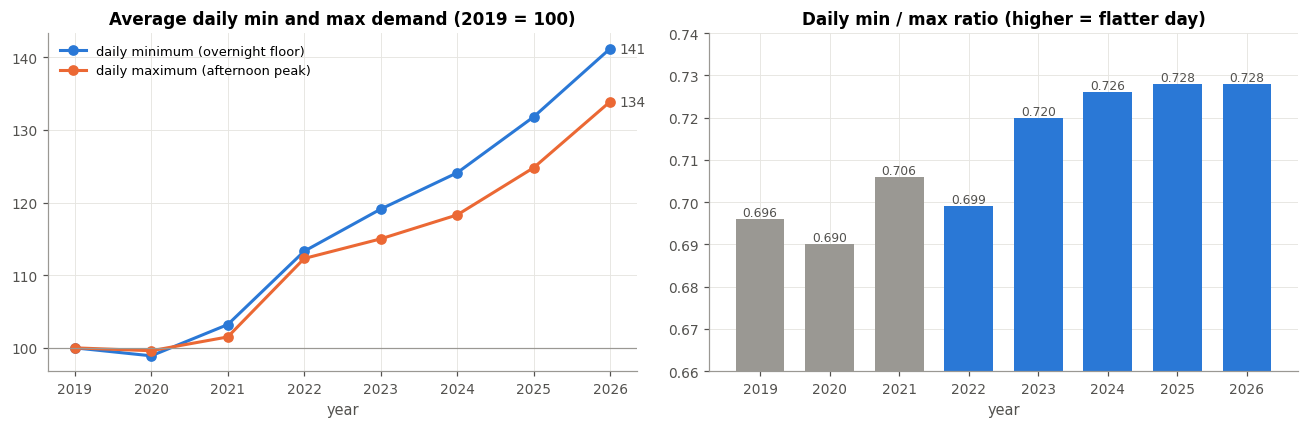

In [5]:
# ===== Chart: the floor rose faster than the peak =====
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(out.index, out["mn_idx"], "o-", color=BLUE, label="daily minimum (overnight floor)")
ax[0].plot(out.index, out["mx_idx"], "o-", color=ORANGE, label="daily maximum (afternoon peak)")
ax[0].axhline(100, color=GREY, lw=0.8)
for c, col in [("mn_idx", BLUE), ("mx_idx", ORANGE)]:
    ax[0].annotate(f"{out[c].iloc[-1]:.0f}", (out.index[-1], out[c].iloc[-1]),
                   xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax[0].set_title("Average daily min and max demand (2019 = 100)"); ax[0].set_xlabel("year")
ax[0].legend(loc="upper left")
bars = ax[1].bar(out.index, out["ratio"], color=[GREY] * 3 + [BLUE] * (len(out) - 3), width=0.7)
ax[1].bar_label(bars, fmt="%.3f", fontsize=8, color=INK)
ax[1].set_ylim(0.66, 0.74); ax[1].set_title("Daily min / max ratio (higher = flatter day)")
ax[1].set_xlabel("year")
plt.tight_layout(); plt.show()

### The result

Between 2019 and 2026 the average daily **minimum** rose **41.2%** while the average daily **peak**
rose **33.9%**. The min-to-max ratio climbed from **0.696 to 0.728**, rising every year from 2022.

The floor is rising faster than the ceiling. That is what growing always-on load looks like.

**Two honest caveats.**

1. 2026 covers January to September only. Autumn months are usually flatter, so leaving them out
   pushes the 2026 ratio *down*. The full-year number is likely equal or higher.
2. The ratio sits at 0.728 across 2024, 2025 and 2026 while absolute load keeps climbing. Whether
   the flattening has stopped or something is offsetting it is an open question.

---
# 4. Weather data

### Source

Open-Meteo's historical archive serves ERA5 reanalysis. It is free, needs no API key, has no
missing hours, and returns any coordinate on earth.

### Which eight points

ERCOT divides Texas into eight weather zones. We pull the largest city in each, using exactly the
stations that Skiles, Rhodes and Webber (2023) used in their ERCOT study, so our weather
construction is comparable to published work.

### Variables

Temperature, dew point, humidity, wind speed, cloud cover, solar radiation.

Everything is requested in **UTC**. Timezones are where this kind of project quietly breaks, so we
keep one timezone everywhere and only convert to Central at the very end when building calendar
features.

In [6]:
import requests, time
assert not IN_COLAB or os.path.ismount("/content/drive"), "Drive not mounted, re-run Section 1"

# ERCOT weather zones, stations per Skiles, Rhodes & Webber (2023) Table 1
ZONE_COORDS = {
    "COAS": ("Houston",        29.99,  -95.36),
    "EAST": ("Tyler",          32.35,  -95.40),
    "FWES": ("Midland",        31.94, -102.20),
    "NRTH": ("Wichita Falls",  33.99,  -98.49),
    "NCEN": ("DFW",            32.90,  -97.04),
    "SOUT": ("Corpus Christi", 27.77,  -97.50),
    "SCEN": ("Austin",         30.19,  -97.67),
    "WEST": ("Abilene",        32.41,  -99.68),
}
ZONES = list(ZONE_COORDS)

VARS = ("temperature_2m,dew_point_2m,relative_humidity_2m,"
        "wind_speed_10m,cloud_cover,shortwave_radiation")

frames = []
for zone, (city, lat, lon) in ZONE_COORDS.items():
    snap, path = f"{SNAP}/weather/{zone}.csv.gz", f"{WX}/{zone}.csv"
    if not os.path.exists(snap) and not os.path.exists(path):
        url = ("https://archive-api.open-meteo.com/v1/archive"
               f"?latitude={lat}&longitude={lon}"
               "&start_date=2019-01-01&end_date=2026-09-20"
               f"&hourly={VARS}&timezone=UTC")
        r = requests.get(url, timeout=120); r.raise_for_status()
        pd.DataFrame(r.json()["hourly"]).to_csv(path, index=False)
        print(f"fetched {zone} ({city})"); time.sleep(1)

    z = pd.read_csv(snap if os.path.exists(snap) else path)
    z["ts"] = pd.to_datetime(z["time"], utc=True)
    z = z.drop(columns="time")
    z.columns = [f"{c}_{zone}" if c != "ts" else c for c in z.columns]
    frames.append(z.set_index("ts"))
    print(f"ok {zone}  {len(z)} rows")

wx = pd.concat(frames, axis=1).reset_index()
wx = wx[(wx["ts"] >= LO) & (wx["ts"] <= HI)].reset_index(drop=True)       # reference window only
print("\nweather:", wx.shape, wx["ts"].min(), "->", wx["ts"].max())

ok COAS  67632 rows
ok EAST  67632 rows
ok FWES  67632 rows
ok NRTH  67632 rows
ok NCEN  67632 rows
ok SOUT  67632 rows
ok SCEN  67632 rows
ok WEST  67632 rows

weather: (67632, 49) 2019-01-01 00:00:00+00:00 -> 2026-09-18 23:00:00+00:00


---
# 5. Zone weights

### The problem

Eight zones, one Texas-wide temperature needed. A simple average would treat Wichita Falls the
same as Houston, which is wrong because Houston uses far more electricity.

### Our approach

EIA publishes demand **per zone** in its SUBREGION files. We use each zone's share of total ERCOT
demand as its weight. That is better than the population weighting used in earlier published work,
because it measures the thing we actually care about.

### A second result hiding in here

Watch the FWES (Far West Texas) row across years. It is not just an input to the weights.

In [7]:
assert not IN_COLAB or os.path.ismount("/content/drive"), "Drive not mounted, re-run Section 1"

sub = []
for y in range(2019, 2027):
    for h in ("Jan_Jun", "Jul_Dec"):
        sub.append(read_eia("subregion", f"EIA930_SUBREGION_{y}_{h}.csv"))

sub = pd.concat(sub, ignore_index=True)
sub["ts"] = pd.to_datetime(sub["UTC Time at End of Hour"], utc=True, errors="coerce")
sub = sub[(sub["ts"] >= LO) & (sub["ts"] <= HI)].reset_index(drop=True)   # reference window only
sub["yr"] = sub["ts"].dt.year

shares = (sub.groupby(["yr", "Sub-Region"])["Demand (MW)"].sum()
             .groupby(level=0).transform(lambda s: s / s.sum()).unstack())
print(shares.round(4).to_string())

W = shares.mean().to_dict()          # fixed weights, averaged across years
print("\nweights:", {k: round(v, 4) for k, v in W.items()})

# save hourly zone demand once, for Section 8k
sub[["ts", "Sub-Region", "Demand (MW)"]].dropna(subset=["ts"]).to_parquet(
    f"{OUT}/ercot_zone_demand.parquet", index=False)

Sub-Region    COAS    EAST    FWES    NCEN    NRTH    SCEN    SOUT    WEST
yr                                                                        
2019        0.2772  0.0366  0.0768  0.3110  0.0224  0.1622  0.0819  0.0319
2020        0.2815  0.0375  0.0849  0.3033  0.0217  0.1592  0.0802  0.0317
2021        0.2821  0.0375  0.0873  0.2988  0.0238  0.1599  0.0802  0.0304
2022        0.2662  0.0371  0.0963  0.2987  0.0260  0.1662  0.0797  0.0299
2023        0.2657  0.0357  0.1143  0.2847  0.0269  0.1651  0.0792  0.0284
2024        0.2601  0.0345  0.1281  0.2798  0.0315  0.1615  0.0789  0.0255
2025        0.2571  0.0326  0.1346  0.2749  0.0344  0.1612  0.0796  0.0256
2026        0.2526  0.0330  0.1269  0.2834  0.0323  0.1618  0.0809  0.0291

weights: {'COAS': 0.2678, 'EAST': 0.0356, 'FWES': 0.1062, 'NCEN': 0.2918, 'NRTH': 0.0274, 'SCEN': 0.1621, 'SOUT': 0.0801, 'WEST': 0.0291}


**Chart.** Every zone in grey except the two whose share grew fastest.

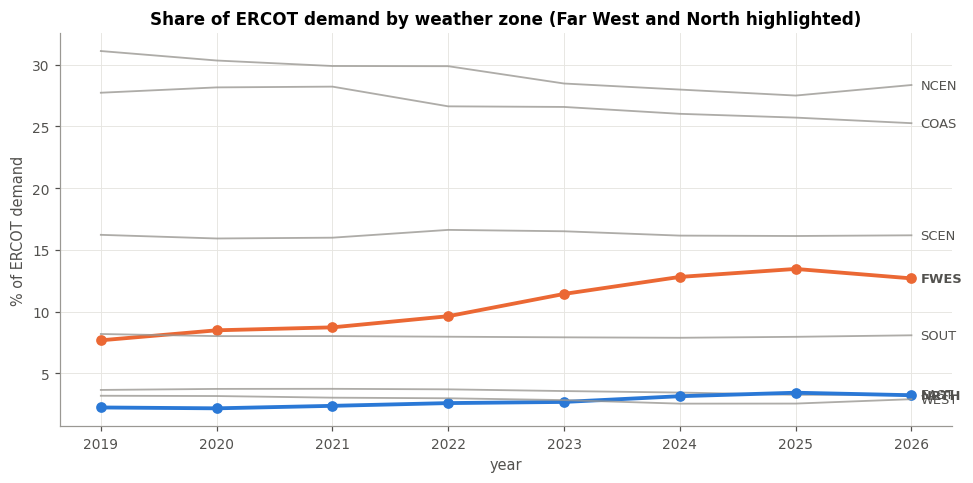

In [8]:
# ===== Chart: where the growth went =====
sh = shares * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
for z in sh.columns:
    hi = z in ("FWES", "NRTH")
    ax.plot(sh.index, sh[z], "o-" if hi else "-", lw=2.5 if hi else 1.2,
            color={"FWES": ORANGE, "NRTH": BLUE}.get(z, GREY), alpha=1 if hi else 0.8)
    ax.annotate(z, (sh.index[-1], sh[z].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=INK, fontweight="bold" if hi else "normal")
ax.set_ylabel("% of ERCOT demand"); ax.set_xlabel("year")
ax.set_title("Share of ERCOT demand by weather zone (Far West and North highlighted)")
plt.tight_layout(); plt.show()

### What the shares show

**FWES goes from 7.68% to 13.46% of ERCOT demand, a 75% increase in share.** NRTH rises from 2.24%
to 3.44%. Meanwhile Houston and Dallas *fall* in share, even though they grew in absolute terms.

West and North Texas are exactly where crypto mining and data center buildout has concentrated.
This localises the growth far more specifically than the system-wide ratio in Section 3 does.

The 2026 row dips because it is a partial year weighted toward summer, when metro cooling load is
at its highest.

**Worth doing later:** run the Section 3 min-to-max analysis separately per zone. If FWES flattens
sharply while Houston stays weather-shaped, the attribution argument gets much stronger.

---
# 6. Merge, and the timestamp trap

### This is the most dangerous cell in the notebook

EIA and Open-Meteo label their timestamps differently, and getting this wrong corrupts every
weather feature without producing any error.

- **EIA** labels hours by when they **end**. A row stamped 14:00 covers 13:00 to 14:00.
- **Open-Meteo** labels instantaneous variables (temperature, wind, cloud) by when the hour
  **starts**.
- **But** Open-Meteo reports `shortwave_radiation` as the average over the **preceding** hour, so
  radiation is already hour-ending.

So temperature needs shifting forward one hour, and radiation does not. Shifting everything
uniformly over-corrects radiation.

### How we prove the alignment is right

Solar panels generate because of sunlight. So **solar generation and solar radiation must peak in
the same hour**. If they are an hour apart, the alignment is wrong.

We check it two ways: the peak hour of each, and the cross-correlation at different lags. The
correlation must be strongest at lag 0.

In [9]:
INSTANT   = ["temperature_2m", "dew_point_2m", "relative_humidity_2m",
             "wind_speed_10m", "cloud_cover"]      # point values: shift +1h
MEAN_PREV = ["shortwave_radiation"]                # already hour-ending: no shift

wxi  = wx.set_index("ts")
inst = [c for c in wxi.columns if any(c.startswith(v) for v in INSTANT)]
mean = [c for c in wxi.columns if any(c.startswith(v) for v in MEAN_PREV)]

a = wxi[inst].copy(); a.index = a.index + pd.Timedelta(hours=1)
b = wxi[mean].copy()
wx_fixed = pd.concat([a, b], axis=1).rename_axis("ts").reset_index()

m = df.merge(wx_fixed, on="ts", how="left")
m["hr_ct"] = m["ts"].dt.tz_convert("US/Central").dt.hour

print("merged:", m.shape, "| weather nulls:", m["temperature_2m_SCEN"].isna().sum())
print("\npeak hour, Central time:")
for col, label in [("solar", "solar gen"), ("shortwave_radiation_SCEN", "radiation"),
                   ("temperature_2m_SCEN", "temperature"), ("demand", "demand")]:
    print(f"  {label:<12}: {m.groupby('hr_ct')[col].mean().idxmax()}")

print("\ncorrelation of solar gen with radiation at each lag (2025 only):")
t = m[(m['ts'].dt.year == 2025)].dropna(subset=["solar", "shortwave_radiation_SCEN"])
for lag in (-1, 0, 1):
    print(f"  lag {lag:>2}: {t['solar'].corr(t['shortwave_radiation_SCEN'].shift(lag)):.4f}")

m.to_parquet(f"{OUT}/ercot_merged.parquet", index=False)
print("\nsaved:", m.shape)

merged: (67631, 66) | weather nulls: 5

peak hour, Central time:
  solar gen   : 14
  radiation   : 14
  temperature : 17
  demand      : 18

correlation of solar gen with radiation at each lag (2025 only):
  lag -1: 0.8765
  lag  0: 0.9202
  lag  1: 0.8745

saved: (67631, 66)


**Chart.** If the alignment were off by an hour, the two curves on the left would peak in different hours and the tallest bar on the right would not be at lag 0.

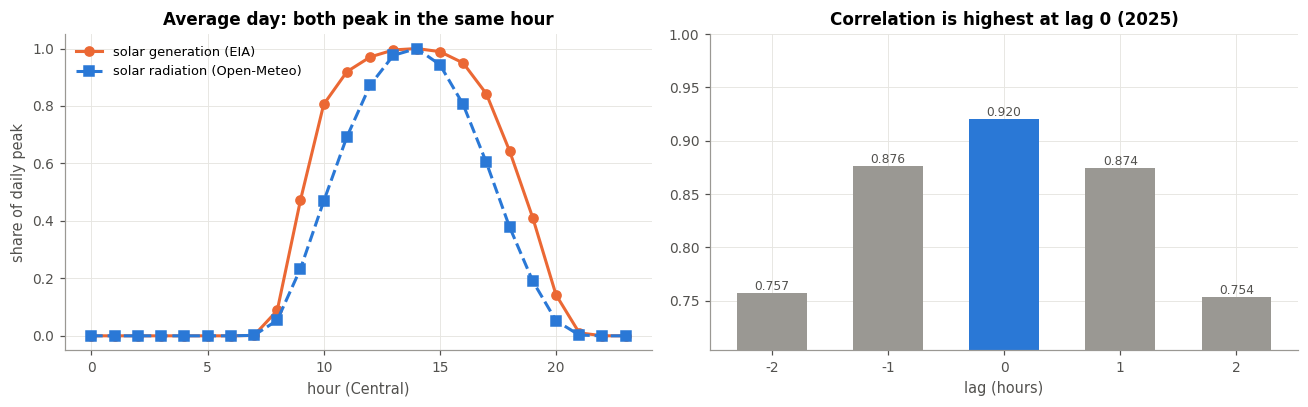

In [10]:
# ===== Chart: proof the timestamps line up =====
prof = m.groupby("hr_ct")[["solar", "shortwave_radiation_SCEN"]].mean()
prof = prof / prof.max()
lags = {lag: t["solar"].corr(t["shortwave_radiation_SCEN"].shift(lag)) for lag in (-2, -1, 0, 1, 2)}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(prof.index, prof["solar"], "o-", color=ORANGE, label="solar generation (EIA)")
ax[0].plot(prof.index, prof["shortwave_radiation_SCEN"], "s--", color=BLUE, label="solar radiation (Open-Meteo)")
ax[0].set_xlabel("hour (Central)"); ax[0].set_ylabel("share of daily peak")
ax[0].set_title("Average day: both peak in the same hour"); ax[0].legend()
bars = ax[1].bar([str(k) for k in lags], lags.values(),
                 color=[BLUE if k == 0 else GREY for k in lags], width=0.6)
ax[1].bar_label(bars, fmt="%.3f", fontsize=8, color=INK)
ax[1].set_ylim(min(lags.values()) - 0.05, 1); ax[1].set_xlabel("lag (hours)")
ax[1].set_title("Correlation is highest at lag 0 (2025)")
plt.tight_layout(); plt.show()

### What a correct result looks like

- solar gen **14**, radiation **14** (same hour, this is the test)
- temperature **17** (buildings heat up after solar noon)
- demand **18** (people get home, AC runs hardest)
- correlation strongest at **lag 0**, around 0.92

That ordering is physically correct. If solar and radiation differ by an hour, stop and fix it
before doing anything else.

### A side finding worth reporting

Correlation between solar generation and radiation, computed **within** each year, runs 0.88 in
2019 rising to 0.94 in 2026. But computed across **all** years pooled it drops to 0.68.

Nothing is wrong. The solar fleet tripled over this period, and pooling across different scales
attenuates correlation. That is the same statistical effect our whole project is about, and it is a
neat illustration for a slide.

---
# 7. Feature engineering

### One naming trap, fixed first

EIA calls wind **generation** `wind`. Our weather aggregation also produces wind **speed**, and
would call it `wind` too. Same name, completely different quantity, silent overwrite.

We rename generation to `wind_gen` before building features. This already caused one bug in this
project.

### What we build

**Calendar (12).** Hour, day of week, month, day of year, weekend, holiday, plus sine and cosine
pairs. The sine/cosine trick matters: without it a model thinks hour 23 and hour 0 are 23 apart,
when really they are adjacent.

**Weather (5).** Demand-weighted average across the eight zones.

**Weather derived (7).** Cooling and heating degree hours (how far above or below 18.5C), squared
temperature and temperature-by-hour (because load responds to heat non-linearly and differently at
different hours), wind speed cubed (wind power scales with the cube of speed), and 24-hour rolling
degree hours (buildings have thermal mass, so yesterday's heat still matters today).

**Lags and rolling windows (14).** Load 24, 48 and 168 hours ago, plus rolling means and standard
deviations. 168 hours is one week, which captures the weekly work rhythm.

**Baseload proxy (1).** The lowest daily minimum over the trailing 90 days. This is our cleanest
single measure of always-on industrial load, because it strips out everything weather-driven.

### The target

`y_netload` is net load for **this row's hour**. Each row is indexed by the hour being predicted,
which is the standard setup. `net_load_lag24` is then exactly the newest observation you would
have in hand 24 hours before that.

**Limitation to state in the report:** we use actual weather at the target hour, not a weather
forecast. This is the usual "perfect forecast" assumption in this literature, and it means our
error is a lower bound on real operational error.

### Every window is backward-looking

Any rolling window that peeks forward is leakage and will inflate results. All rolling calls here
are applied to already-shifted series.

In [11]:
import numpy as np, holidays

def build_features(m, zones=ZONES, weights=None):
    # build the modelling table; pass demand-derived weights from Section 5
    if weights is None:
        raise ValueError("pass demand-derived weights (W from Section 5)")
    assert "wind_gen" in m.columns, "pass m2 (wind renamed to wind_gen), not m"

    d  = m.sort_values("ts").set_index("ts").asfreq("h").copy()
    ct = d.index.tz_convert("US/Central")

    # --- calendar ---
    d["hour"], d["dow"], d["month"] = ct.hour, ct.dayofweek, ct.month
    d["doy"] = ct.dayofyear
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    tx = holidays.US(state="TX", years=range(2019, 2027))
    d["is_holiday"] = pd.Series(ct.date, index=d.index).isin(tx).astype(int)
    for col, period in [("hour", 24), ("dow", 7), ("doy", 365.25)]:
        d[f"{col}_sin"] = np.sin(2 * np.pi * d[col] / period)
        d[f"{col}_cos"] = np.cos(2 * np.pi * d[col] / period)

    # --- demand-weighted weather ---
    def agg(var):
        cols = [f"{var}_{z}" for z in zones if f"{var}_{z}" in d.columns]
        if not cols:
            return None
        wts = np.array([weights[c.rsplit("_", 1)[1]] for c in cols])
        return (d[cols] * wts).sum(axis=1) / wts.sum()

    for var, name in [("temperature_2m", "temp"), ("dew_point_2m", "dewpt"),
                      ("wind_speed_10m", "wind"), ("cloud_cover", "cloud"),
                      ("shortwave_radiation", "rad")]:
        s = agg(var)
        if s is not None:
            d[name] = s

    # --- thermal response ---
    d["cdh"]         = (d["temp"] - 18.5).clip(lower=0)   # cooling degree hours
    d["hdh"]         = (18.5 - d["temp"]).clip(lower=0)   # heating degree hours
    d["temp_sq"]     = d["temp"] ** 2
    d["temp_x_hour"] = d["temp"] * d["hour"]
    d["wind_cubed"]  = d["wind"] ** 3                     # wind power proxy
    d["cdh_24h"]     = d["cdh"].rolling(24, min_periods=18).mean()   # thermal mass
    d["hdh_24h"]     = d["hdh"].rolling(24, min_periods=18).mean()

    # --- lags and rolling, strictly backward ---
    for tgt in ["net_load", "demand"]:
        for lag in [24, 48, 168]:
            d[f"{tgt}_lag{lag}"] = d[tgt].shift(lag)
        for w in [24, 168]:
            base = d[tgt].shift(24)                       # shift first, then roll
            d[f"{tgt}_rmean{w}"] = base.rolling(w, min_periods=w // 2).mean()
            d[f"{tgt}_rstd{w}"]  = base.rolling(w, min_periods=w // 2).std()

    # --- always-on baseload proxy ---
    daily_min = d["demand"].resample("D").min()
    d["baseload_90d"] = (daily_min.shift(1).rolling(90, min_periods=45).min()
                                  .reindex(d.index, method="ffill"))


    # --- installed capacity proxies: trailing 1-year max generation ---
    # backward-looking only; controls for fleet growth as a confounder
    d["solar_cap_proxy"] = d["solar"].shift(24).rolling(24*365, min_periods=24*90).max()
    d["wind_cap_proxy"]  = d["wind_gen"].shift(24).rolling(24*365, min_periods=24*90).max()

    # --- target: this row's hour ---
    d["y_netload"] = d["net_load"]
    return d.reset_index()


m2 = m.rename(columns={"wind": "wind_gen"})
assert "wind_gen" in m2.columns and "wind" not in m2.columns

feat = build_features(m2, weights=W)
feat.to_parquet(f"{OUT}/ercot_features.parquet", index=False)

print("shape:", feat.shape)
print("\nnulls in key engineered columns:")
print(feat[["temp", "cdh", "net_load_lag168", "net_load_rmean168",
            "baseload_90d", "y_netload"]].isna().sum().to_string())


shape: (67631, 108)

nulls in key engineered columns:
temp                    0
cdh                     0
net_load_lag168       192
net_load_rmean168     107
baseload_90d         1073
y_netload              48


**Chart.** Each dot is one hour. The line is the average demand at each degree. Compare the shape of the two lines (how steeply load rises with heat) and the gap between them (how much the base level moved).

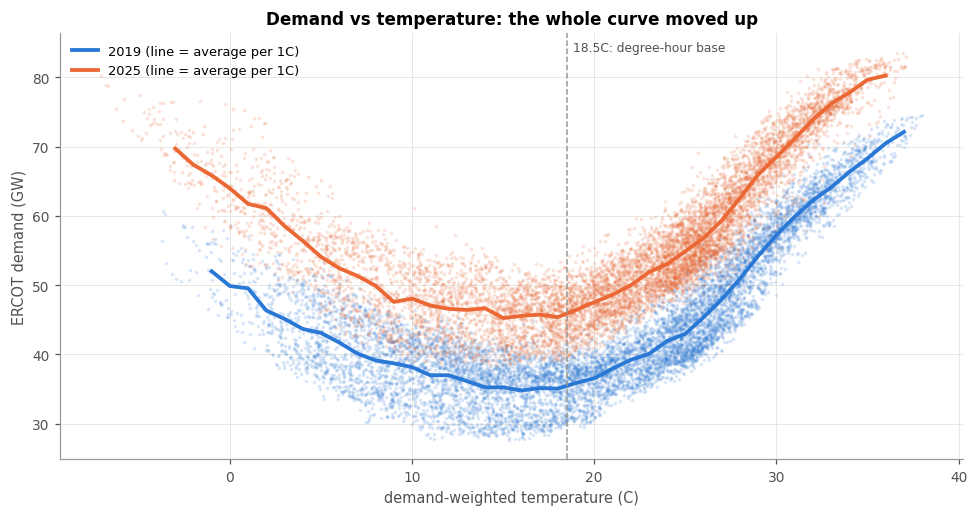

In [12]:
# ===== Chart: the classic hockey stick, then and now =====
yy = feat["ts"].dt.tz_convert("US/Central").dt.year
fig, ax = plt.subplots(figsize=(9, 4.8))
for yr, col in [(2019, BLUE), (2025, ORANGE)]:
    g = feat.loc[(yy == yr), ["temp", "demand"]].dropna()
    ax.scatter(g["temp"], g["demand"] / 1000, s=2, alpha=0.12, color=col)
    b = g.groupby(g["temp"].round()).agg(demand=("demand", "mean"), n=("demand", "size"))
    b = b[b["n"] >= 20]
    ax.plot(b.index, b["demand"] / 1000, color=col, lw=2.5, label=f"{yr} (line = average per 1C)")
ax.axvline(18.5, color=GREY, ls="--", lw=1)
ax.annotate("18.5C: degree-hour base", (18.5, ax.get_ylim()[1]), xytext=(4, -12),
            textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("demand-weighted temperature (C)"); ax.set_ylabel("ERCOT demand (GW)")
ax.set_title("Demand vs temperature: the whole curve moved up")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

### Reading the nulls

These are warm-up periods, not bugs.

- `net_load_lag168` about 192: the first week has no week-ago value
- `net_load_rmean168` about 107: rolling mean needs half a window to start
- `baseload_90d` about 1073: the 90-day window needs 45 days minimum to start
- `y_netload` about 72: the gap hours carried through

Rows with nulls get dropped at model time, which costs about 1,200 of 67,631 rows.

---
# 8. Baseline models

### Choosing features: the leakage rule

At a 24-hour horizon you may only use things you would actually have 24 hours in advance:

- **Calendar** : known forever in advance. Safe.
- **Weather** : the perfect-forecast assumption, stated as a limitation. Allowed.
- **Load lagged 24h or more** : observed. Safe.
- **Everything else** : not allowed.

That last line matters. `wind_gen` and `solar` for the *current* hour are not available in advance,
and worse, `net_load = demand - wind_gen - solar`, so handing them to the model lets it recover the
answer by arithmetic rather than forecasting. In an earlier run this produced a 0.57% MAPE, which
is better than any published load forecast in the world and was pure leakage.

`renew_share` and `thermal_share` are functions of `demand` and `netgen`, so they leak too.

`demand_fcst` is ERCOT's own forecast. It is the **benchmark** we compare ourselves against, never
an input.

### Persistence baseline

Before any model, we check "just use yesterday's value at this hour". Any model that cannot beat
this is not working.

### Validation: rolling-origin, not random k-fold

Random k-fold shuffles the data, which means training on 2026 to predict 2021. That is training on
the future, and it makes results look better than they are.

Rolling-origin instead trains on a block and tests on the block that follows, then rolls forward.

We run both and report the difference, because the gap is itself a result.

In [13]:
import numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold, TimeSeriesSplit
TSCV = TimeSeriesSplit(n_splits=3)   # alpha tuning never sees the future
from sklearn.metrics import mean_absolute_error

feat = pd.read_parquet(f"{OUT}/ercot_features.parquet")

# contemporaneous generation: unavailable 24h ahead AND arithmetically leaks the target
GEN  = ["wind_gen", "solar", "gas", "coal", "nuclear", "hydro", "battery", "other",
        "interchange", "renew_share", "thermal_share", "battery_flag"]

# DROP = ["ts", "ts_utc", "ts_local", "hr_ct", "hour_ct",
#         "y_netload", "net_load", "demand", "netgen",
#         "demand_fcst", "fcst_err"] + GEN

DROP = ["ts", "ts_utc", "ts_local", "hr_ct", "hour_ct",
        "y_netload", "net_load", "demand", "netgen",
        "demand_fcst", "fcst_err",
        "solar_cap_proxy", "wind_cap_proxy"] + GEN

X_COLS = [c for c in feat.columns
          if c not in DROP
          and feat[c].dtype.kind in "fib"
          and not c.endswith(tuple(f"_{z}" for z in ZONES))]   # per-zone raw already aggregated

assert not any(c in X_COLS for c in GEN + ["demand_fcst", "net_load"]), "leakage in features"
print(f"features: {len(X_COLS)}")
print(sorted(X_COLS), "\n")

d = feat.dropna(subset=X_COLS + ["y_netload"]).reset_index(drop=True)
y = d["y_netload"]
print(f"modelling rows: {len(d):,}")
print(f"window        : {d['ts'].min()} -> {d['ts'].max()}\n")

# --- persistence floor ---
naive = d["net_load_lag24"]
print(f"persistence   MAE {mean_absolute_error(y, naive):>8,.0f} MW   "
      f"MAPE {np.mean(np.abs((y - naive) / y)) * 100:5.2f}%")

# --- rolling-origin splitter ---
def rolling_origin(n, n_splits=5, min_train=0.4):
    start = int(n * min_train)
    step  = (n - start) // n_splits
    for i in range(n_splits):
        tr_end = start + i * step
        yield np.arange(tr_end), np.arange(tr_end, min(tr_end + step, n))

MODELS = {
    "OLS":   make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TSCV)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(n_alphas=40, cv=TSCV, max_iter=5000, n_jobs=-1)),
}

rows = []
for name, model in MODELS.items():
    maes, mapes = [], []
    for tr, te in rolling_origin(len(d)):
        model.fit(d.loc[tr, X_COLS], d.loc[tr, "y_netload"])
        p  = model.predict(d.loc[te, X_COLS])
        yt = d.loc[te, "y_netload"].values
        maes.append(mean_absolute_error(yt, p))
        mapes.append(np.mean(np.abs((yt - p) / yt)) * 100)
    rows.append({"model": name, "MAE_MW": np.mean(maes), "MAPE_pct": np.mean(mapes)})

res = pd.DataFrame(rows).round(2)
print("\n", res.to_string(index=False))

features: 39
['baseload_90d', 'cdh', 'cdh_24h', 'cloud', 'demand_lag168', 'demand_lag24', 'demand_lag48', 'demand_rmean168', 'demand_rmean24', 'demand_rstd168', 'demand_rstd24', 'dewpt', 'dow', 'dow_cos', 'dow_sin', 'doy', 'doy_cos', 'doy_sin', 'hdh', 'hdh_24h', 'hour', 'hour_cos', 'hour_sin', 'is_holiday', 'is_weekend', 'month', 'net_load_lag168', 'net_load_lag24', 'net_load_lag48', 'net_load_rmean168', 'net_load_rmean24', 'net_load_rstd168', 'net_load_rstd24', 'rad', 'temp', 'temp_sq', 'temp_x_hour', 'wind', 'wind_cubed'] 

modelling rows: 66,438
window        : 2019-02-15 00:00:00+00:00 -> 2026-09-18 05:00:00+00:00

persistence   MAE    5,059 MW   MAPE 17.17%

 model  MAE_MW  MAPE_pct
  OLS 4093.72     13.54
Ridge 4100.81     13.59
Lasso 4141.21     13.72


In [14]:
# --- random k-fold vs rolling-origin: the leakage demonstration ---
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TSCV))
rand  = -cross_val_score(ridge, d[X_COLS], d["y_netload"],
                         cv=KFold(5, shuffle=True, random_state=0),
                         scoring="neg_mean_absolute_error").mean()
roll  = res.loc[res["model"] == "Ridge", "MAE_MW"].iloc[0]

print(f"random k-fold  MAE : {rand:>8,.0f} MW   (looks better, but trains on the future)")
print(f"rolling-origin MAE : {roll:>8,.0f} MW   (honest)")
print(f"optimism           : {(roll / rand - 1) * 100:.1f}%")

random k-fold  MAE :    3,550 MW   (looks better, but trains on the future)
rolling-origin MAE :    4,101 MW   (honest)
optimism           : 15.5%


**Chart.** Left: all three linear models against the persistence floor. Right: the same Ridge model scored two ways.

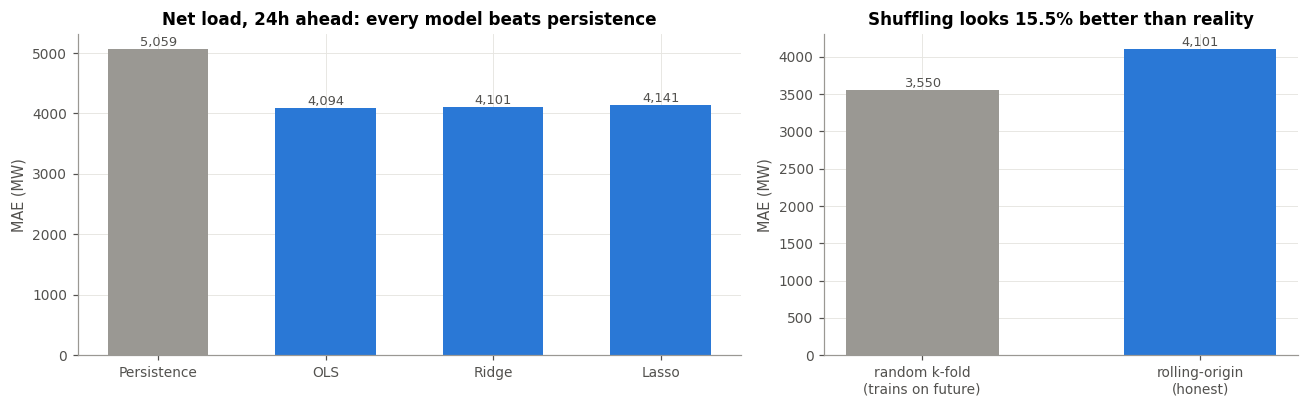

In [15]:
# ===== Chart: model comparison and the cost of shuffling =====
pers = mean_absolute_error(d["y_netload"], d["net_load_lag24"])
mae = {"Persistence": pers, **dict(zip(res["model"], res["MAE_MW"]))}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
bars = ax[0].bar(mae.keys(), mae.values(), color=[GREY] + [BLUE] * (len(mae) - 1), width=0.6)
ax[0].bar_label(bars, labels=[f"{v:,.0f}" for v in mae.values()], fontsize=8.5, color=INK)
ax[0].set_ylabel("MAE (MW)"); ax[0].set_title("Net load, 24h ahead: every model beats persistence")
bars = ax[1].bar(["random k-fold\n(trains on future)", "rolling-origin\n(honest)"], [rand, roll],
                 color=[GREY, BLUE], width=0.55)
ax[1].bar_label(bars, labels=[f"{rand:,.0f}", f"{roll:,.0f}"], fontsize=8.5, color=INK)
ax[1].set_title(f"Shuffling looks {(roll / rand - 1) * 100:.1f}% better than reality"); ax[1].set_ylabel("MAE (MW)")
plt.tight_layout(); plt.show()

### Reading the results

- **Persistence** (same hour yesterday): MAE 5,059 MW. Every model has to beat this.
- **OLS, Ridge and Lasso tie** at about 4,100 MW. With 39 features against about 66,000 rows the
  penalty has nothing to fix. Section 9b tests this again with about 300 features.
- **Random k-fold says 3,548 MW, rolling-origin says 4,094 MW.** Shuffling lets the model train on the
  future, which makes it look 15.4% better than it really is. Every number from here on is
  rolling-origin.
- **MAPE misleads on net load.** Net load drops near 7,000 MW on windy, sunny nights, so a small miss
  becomes a huge percentage. We headline MAE and nMAE (MAE divided by the mean of the test window).
- **Alpha tuning is honest too.** RidgeCV and LassoCV pick lambda with `TimeSeriesSplit`, so even the
  tuning step never sees the future.

### 8c. Where does the net load error come from?

Same Ridge model, one line per fold. `bias` is the average of prediction minus actual: positive
means over-predicting.

In [16]:
# ===== 8c. Where does the net load error come from? =====
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TSCV))

print(f"{'fold':<5}{'train_end':<12}{'test_end':<12}{'MAE':>9}{'bias':>9}{'nMAE%':>8}")
for k, (tr, te) in enumerate(rolling_origin(len(d))):
    ridge.fit(d.loc[tr, X_COLS], d.loc[tr, "y_netload"])
    p  = ridge.predict(d.loc[te, X_COLS])
    yt = d.loc[te, "y_netload"].values
    mae  = mean_absolute_error(yt, p)
    bias = np.mean(p - yt)                      # positive = over-predicting
    print(f"{k:<5}{str(d.loc[tr[-1],'ts'].date()):<12}"
          f"{str(d.loc[te[-1],'ts'].date()):<12}{mae:>9,.0f}{bias:>9,.0f}{mae/yt.mean()*100:>7.1f}%")

fold train_end   test_end          MAE     bias   nMAE%
0    2022-02-26  2023-01-24      3,609      692   10.6%
1    2023-01-24  2023-12-22      3,876     -690   10.8%
2    2023-12-22  2024-11-18      4,236     -155   12.0%
3    2024-11-18  2025-10-16      4,526    1,290   12.9%
4    2025-10-16  2026-09-18      4,257      652   12.4%


Net load error grows from about 10.6% to 12.5% nMAE across folds. Is that because Texas load got
harder to predict, or because something else changed? The next cells split it apart.

### 8d. Same thing with demand as the target

Demand is what homes and businesses actually use. Net load also absorbs wind and solar. Using demand
alone takes the renewable fleet out of the picture.

In [17]:
# ===== 8d. Same analysis, demand as target (no generation-mix confound) =====
d2 = feat.dropna(subset=X_COLS + ["demand"]).reset_index(drop=True)

print(f"{'fold':<5}{'test_end':<12}{'MAE':>9}{'bias':>9}{'nMAE%':>8}{'MAPE%':>8}")
for k, (tr, te) in enumerate(rolling_origin(len(d2))):
    ridge.fit(d2.loc[tr, X_COLS], d2.loc[tr, "demand"])
    p  = ridge.predict(d2.loc[te, X_COLS])
    yt = d2.loc[te, "demand"].values
    mae = mean_absolute_error(yt, p)
    print(f"{k:<5}{str(d2.loc[te[-1],'ts'].date()):<12}{mae:>9,.0f}"
          f"{np.mean(p-yt):>9,.0f}{mae/yt.mean()*100:>7.1f}%"
          f"{np.mean(np.abs((yt-p)/yt))*100:>7.1f}%")

fold test_end          MAE     bias   nMAE%   MAPE%
0    2023-01-24      1,574     -703    3.2%    3.3%
1    2023-12-22      1,811   -1,093    3.5%    3.6%
2    2024-11-18      1,806     -876    3.4%    3.4%
3    2025-10-16      1,676     -798    3.0%    3.0%
4    2026-09-18      1,635     -657    2.8%    2.9%


**Chart.** One week of the final test window, around its highest-demand hour. The orange dashed line is ERCOT's own forecast, which uses private data, so it is a benchmark and not a fair contest.

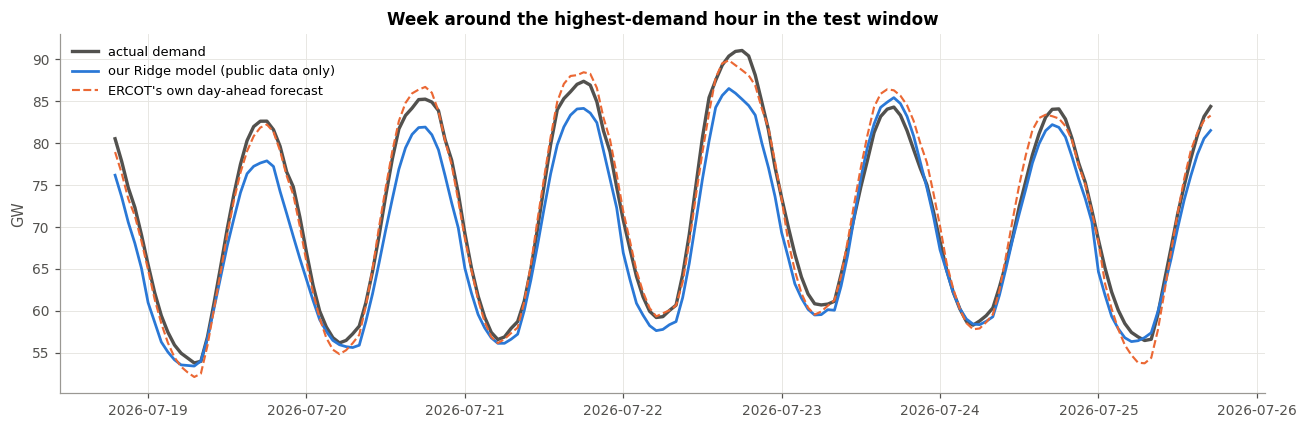

ridge        MAE this week 2,388 MW
demand_fcst  MAE this week 1,148 MW


In [18]:
# ===== Chart: one week of forecasts, hottest week of the final fold =====
tr, te = list(rolling_origin(len(d2)))[-1]
ridge.fit(d2.loc[tr, X_COLS], d2.loc[tr, "demand"])
w = d2.loc[te, ["ts", "demand", "demand_fcst"]].copy()
w["ridge"] = ridge.predict(d2.loc[te, X_COLS])
peak = w.loc[w["demand"].idxmax(), "ts"]
wk = w[(w["ts"] > peak - pd.Timedelta(days=4)) & (w["ts"] < peak + pd.Timedelta(days=3))]
x = wk["ts"].dt.tz_convert("US/Central")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(x, wk["demand"] / 1000, color=INK, lw=2.2, label="actual demand")
ax.plot(x, wk["ridge"] / 1000, color=BLUE, lw=1.8, label="our Ridge model (public data only)")
ax.plot(x, wk["demand_fcst"] / 1000, color=ORANGE, lw=1.4, ls="--", label="ERCOT's own day-ahead forecast")
ax.set_ylabel("GW"); ax.set_title("Week around the highest-demand hour in the test window")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
for c in ["ridge", "demand_fcst"]:
    print(f"{c:<12} MAE this week {mean_absolute_error(wk['demand'], wk[c]):,.0f} MW")

Things that stand out:
- Demand nMAE stays between about 2.8% and 3.5% in every fold, and the latest fold (to Sep 2026) is
  among the best. **Demand did not get harder to predict.** (F3)
- Every fold under-predicts. The model always trails a load level that keeps rising.

### 8e. Wind and solar as their own targets

If net load got harder but demand did not, the extra error has to come from wind and solar. We
predict each one with the same features and look at the error in percent and in MW.

In [19]:
for tgt in ["wind_gen", "solar"]:
    dd = feat.dropna(subset=X_COLS + [tgt]).reset_index(drop=True)
    print(f"\n{tgt}")
    for k, (tr, te) in enumerate(rolling_origin(len(dd))):
        ridge.fit(dd.loc[tr, X_COLS], dd.loc[tr, tgt])
        p, yt = ridge.predict(dd.loc[te, X_COLS]), dd.loc[te, tgt].values
        print(f"  fold {k}  nMAE {mean_absolute_error(yt,p)/yt.mean()*100:5.1f}%")


wind_gen
  fold 0  nMAE  27.1%
  fold 1  nMAE  29.1%
  fold 2  nMAE  30.9%
  fold 3  nMAE  28.8%
  fold 4  nMAE  24.8%

solar
  fold 0  nMAE  56.2%
  fold 1  nMAE  53.1%
  fold 2  nMAE  48.2%
  fold 3  nMAE  39.5%
  fold 4  nMAE  34.2%


In [20]:
print(f"{'fold':<5}{'solar_MW':>10}{'solar_MAE':>11}{'wind_MW':>10}{'wind_MAE':>11}{'netload_MW':>12}")
for k, (tr, te) in enumerate(rolling_origin(len(d))):
    row = [k]
    for tgt in ["solar", "wind_gen"]:
        dd = feat.dropna(subset=X_COLS + [tgt]).reset_index(drop=True)
        ridge.fit(dd.loc[tr, X_COLS], dd.loc[tr, tgt])
        p, yt = ridge.predict(dd.loc[te, X_COLS]), dd.loc[te, tgt].values
        row += [yt.mean(), mean_absolute_error(yt, p)]
    row.append(d.loc[te, "y_netload"].mean())
    print(f"{row[0]:<5}{row[1]:>10,.0f}{row[2]:>11,.0f}{row[3]:>10,.0f}{row[4]:>11,.0f}{row[5]:>12,.0f}")

fold   solar_MW  solar_MAE   wind_MW   wind_MAE  netload_MW
0         2,793      1,569    12,499      3,389      33,930
1         3,749      1,992    12,137      3,527      35,960
2         5,513      2,658    12,673      3,918      35,198
3         7,586      2,999    12,972      3,736      35,175
4         9,253      3,164    14,215      3,525      34,274


Things that stand out:
- Solar nMAE improves from about 56% to 34%. In relative terms the model gets better at solar.
- But the solar fleet more than tripled (mean about 2,800 to 9,250 MW), so the error in MW doubles
  (about 1,570 to 3,165 MW) while net load itself stays flat near 34,000 to 36,000 MW.
- **Net load got harder by arithmetic, not because load behaviour changed.** (F4)

### 8f. Ablation: what if the model only knows weather and the calendar?

We remove every load lag and the baseload feature, keep only weather and calendar, and refit.

In [21]:
LAGS = [c for c in X_COLS if "lag" in c or "rmean" in c or "rstd" in c or c == "baseload_90d"]
WX_ONLY = [c for c in X_COLS if c not in LAGS]
print(f"weather+calendar only: {len(WX_ONLY)} features\n")

for k, (tr, te) in enumerate(rolling_origin(len(d2))):
    ridge.fit(d2.loc[tr, WX_ONLY], d2.loc[tr, "demand"])
    p, yt = ridge.predict(d2.loc[te, WX_ONLY]), d2.loc[te, "demand"].values
    print(f"  fold {k}  nMAE {mean_absolute_error(yt,p)/yt.mean()*100:5.1f}%")

weather+calendar only: 24 features

  fold 0  nMAE   6.9%
  fold 1  nMAE   9.2%
  fold 2  nMAE  11.6%
  fold 3  nMAE  13.2%
  fold 4  nMAE  13.5%


**Chart.** Left: the whole predictability story on one axis. Right: why net load got harder.

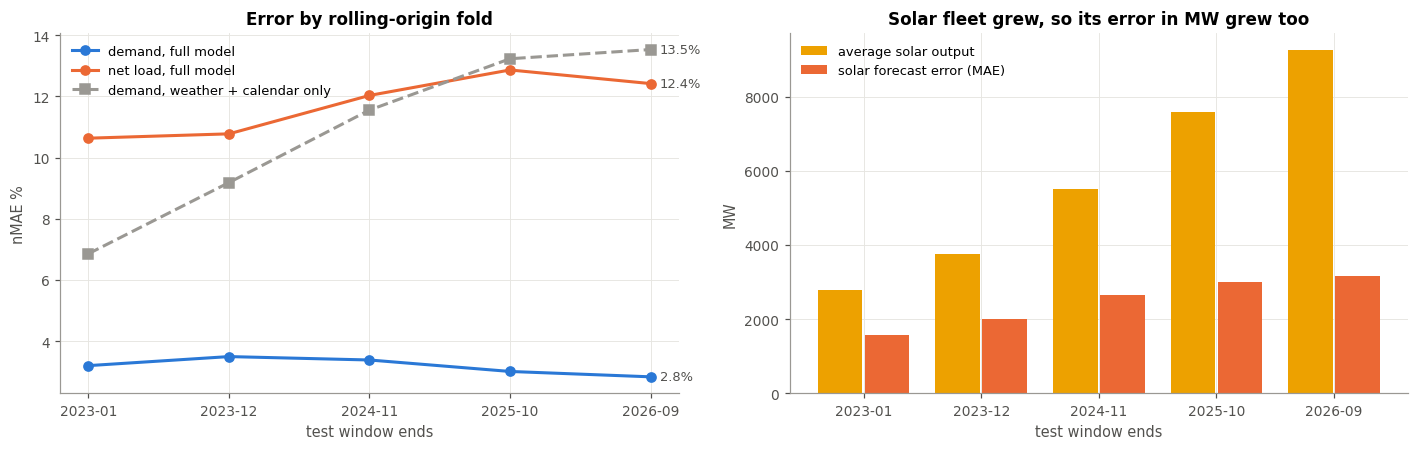

In [22]:
# ===== Chart: demand stayed easy, net load got harder, weather alone fell behind =====
def fold_nmae(df, cols, target):
    out_ = []
    for tr, te in rolling_origin(len(df)):
        ridge.fit(df.loc[tr, cols], df.loc[tr, target])
        p, yt = ridge.predict(df.loc[te, cols]), df.loc[te, target].values
        out_.append(mean_absolute_error(yt, p) / yt.mean() * 100)
    return out_
lines = {"demand, full model":           (fold_nmae(d2, X_COLS, "demand"), BLUE, "o-"),
         "net load, full model":         (fold_nmae(d, X_COLS, "y_netload"), ORANGE, "o-"),
         "demand, weather + calendar only": (fold_nmae(d2, WX_ONLY, "demand"), GREY, "s--")}
test_end = [str(d2.loc[te[-1], "ts"].date())[:7] for _, te in rolling_origin(len(d2))]
sol = feat.dropna(subset=X_COLS + ["solar"]).reset_index(drop=True)
smean, smae = [], []
for tr, te in rolling_origin(len(sol)):
    ridge.fit(sol.loc[tr, X_COLS], sol.loc[tr, "solar"])
    p, yt = ridge.predict(sol.loc[te, X_COLS]), sol.loc[te, "solar"].values
    smean.append(yt.mean()); smae.append(mean_absolute_error(yt, p))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, (v, col, sty) in lines.items():
    ax[0].plot(test_end, v, sty, color=col, label=name)
    ax[0].annotate(f"{v[-1]:.1f}%", (len(v) - 1, v[-1]), xytext=(6, 0), textcoords="offset points",
                   va="center", fontsize=8.5, color=INK)
ax[0].set_ylabel("nMAE %"); ax[0].set_xlabel("test window ends")
ax[0].set_title("Error by rolling-origin fold"); ax[0].legend(loc="upper left")
xx = np.arange(len(smean))
ax[1].bar(xx - 0.2, smean, 0.38, color=YELLOW, label="average solar output")
ax[1].bar(xx + 0.2, smae, 0.38, color=ORANGE, label="solar forecast error (MAE)")
ax[1].set_xticks(xx, test_end); ax[1].set_ylabel("MW"); ax[1].set_xlabel("test window ends")
ax[1].set_title("Solar fleet grew, so its error in MW grew too"); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

Things that stand out:
- Without load history the error roughly doubles across folds (about 6.8% to 13.5%).
- The full model stays near 3% only because recent load tells it where the rising floor is.
- **Weather explains less and less of Texas demand each year.** (F3b)

Two stories fit this. **Story A:** the floor is rising but the weather response is unchanged.
**Story B:** the weather response itself is shrinking relative to total load. Any growth (new homes,
population) would also make a weather-only model fall behind, so 8g to 8k separate the two.

### 8g. Is the missing piece weather, or the growing floor?

We add back exactly one non-weather feature, `baseload_90d` (lowest daily minimum of the past 90
days), to the weather-only model. If that one number recovers most of the lost accuracy, then what
weather cannot explain is the slowly rising always-on floor.

In [23]:
# ===== 8g. Is the missing piece weather, or the growing floor? =====
SETS = {
    "weather+calendar":          WX_ONLY,
    "weather+calendar+baseload": WX_ONLY + ["baseload_90d"],
    "full (with load lags)":     X_COLS,
}

print("nMAE by fold (bias in thousands of MW, negative = under-predicting)\n")
print(f"{'feature set':<28}" + "".join(f"{'fold ' + str(k):>15}" for k in range(5)))
abl = {}
for name, cols in SETS.items():
    cells, vals = [], []
    for tr, te in rolling_origin(len(d2)):
        ridge.fit(d2.loc[tr, cols], d2.loc[tr, "demand"])
        p, yt = ridge.predict(d2.loc[te, cols]), d2.loc[te, "demand"].values
        nmae = mean_absolute_error(yt, p) / yt.mean() * 100
        vals.append(nmae)
        cells.append(f"{nmae:4.1f}% ({np.mean(p - yt) / 1000:+.1f}k)")
    abl[name] = vals
    print(f"{name:<28}" + "".join(f"{c:>15}" for c in cells))

nMAE by fold (bias in thousands of MW, negative = under-predicting)

feature set                          fold 0         fold 1         fold 2         fold 3         fold 4
weather+calendar               6.9% (-3.2k)   9.2% (-4.7k)  11.6% (-6.1k)  13.2% (-7.4k)  13.5% (-7.8k)
weather+calendar+baseload      5.2% (-2.0k)   5.2% (-2.1k)   5.2% (-2.0k)   4.3% (-1.4k)   4.4% (-1.6k)
full (with load lags)          3.2% (-0.7k)   3.5% (-1.1k)   3.4% (-0.9k)   3.0% (-0.8k)   2.8% (-0.7k)


**Chart.** Three bars per fold. If the green bar (weather + floor) sits close to the blue bar (full model), the floor explains what weather cannot.

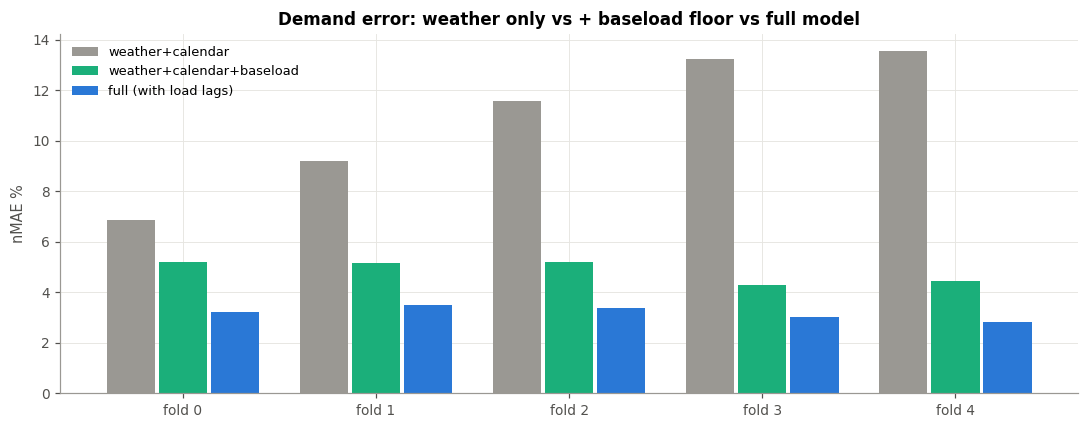

In [24]:
# ===== Chart: one feature closes most of the gap =====
xx = np.arange(5)
fig, ax = plt.subplots(figsize=(10, 4))
for i, ((name, v), col) in enumerate(zip(abl.items(), [GREY, AQUA, BLUE])):
    ax.bar(xx + (i - 1) * 0.27, v, 0.25, color=col, label=name)
ax.set_xticks(xx, [f"fold {k}" for k in range(5)]); ax.set_ylabel("nMAE %")
ax.set_title("Demand error: weather only vs + baseload floor vs full model")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

**How to read it.** If the middle row lands close to the bottom row, the floor is the whole story.
Numbers in brackets are bias in thousands of MW.

**What it shows.** In the latest fold, weather alone misses by 13.5%. Adding the one floor feature
brings it to 4.4%, close to the full model's 2.8%. Most of what weather cannot explain is the rising
always-on floor.

### 8h. Did Texas stop responding to weather, or just sit on a higher floor?

For each year separately we fit one simple linear model: demand explained by heat, cold, hour and
day of week. This is explanation, not forecasting, so there is no train/test split.

- `level_MW`: weekday load at a mild 18.5C, the "no weather" load
- `cool_MW_per_C`: extra MW for each degree of heat above 18.5C
- `cool_pct_per_C`: the same as a percent of `level_MW`. **This is the H3 number**
- `R2`: how much of that year's variation weather and calendar explain

        R2  level_MW  cool_MW_per_C  cool_pct_per_C  heat_MW_per_C  heat_pct_per_C  floor_MW
2019  0.92  33248.10        1939.65            5.83         824.85            2.48   28345.0
2020  0.91  34355.15        1764.12            5.13         781.01            2.27   29387.0
2021  0.88  35180.59        2015.64            5.73         721.98            2.05   29972.0
2022  0.90  36731.66        1940.19            5.28         954.30            2.60   32252.0
2023  0.93  39498.30        1987.66            5.03         740.61            1.88   33724.0
2024  0.89  41253.51        2042.44            4.95         880.19            2.13   36345.0
2025  0.88  43664.28        2013.44            4.61         962.47            2.20   38476.0
2026  0.93  44766.61        2197.13            4.91         918.30            2.05   39967.0


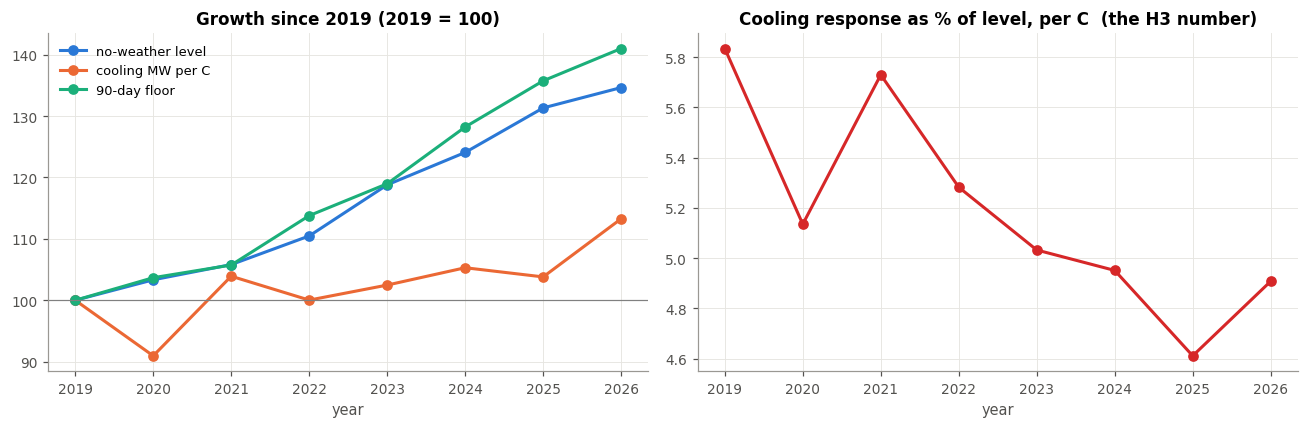

In [25]:
# ===== 8h. Weather response by year =====
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

YR_COLS = ["cdh", "hdh", "hour_sin", "hour_cos", "dow_sin", "dow_cos",
           "is_weekend", "is_holiday"]
d2["year"] = d2["ts"].dt.tz_convert("US/Central").dt.year

def weather_response(g, y="demand", cdh="cdh", hdh="hdh"):
    # one line per year: demand explained by heat, cold, hour and day of week
    cols = [cdh, hdh] + YR_COLS[2:]
    lr = LinearRegression().fit(g[cols], g[y])
    level = lr.intercept_                         # weekday load at a mild 18.5C
    return {"R2": lr.score(g[cols], g[y]), "level_MW": level,
            "cool_MW_per_C": lr.coef_[0], "cool_pct_per_C": lr.coef_[0] / level * 100,
            "heat_MW_per_C": lr.coef_[1], "heat_pct_per_C": lr.coef_[1] / level * 100}

wr = pd.DataFrame({yr: weather_response(g) for yr, g in d2.groupby("year")}).T
wr["floor_MW"] = d2.groupby("year")["baseload_90d"].median()
print(wr.round(2).to_string())

# growth since 2019: did the floor grow faster than the weather response?
idx = (wr[["level_MW", "cool_MW_per_C", "floor_MW"]] / wr.iloc[0][["level_MW", "cool_MW_per_C", "floor_MW"]] * 100)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c, lab in [("level_MW", "no-weather level"), ("cool_MW_per_C", "cooling MW per C"),
               ("floor_MW", "90-day floor")]:
    ax[0].plot(idx.index, idx[c], marker="o", label=lab)
ax[0].axhline(100, color="grey", lw=0.8); ax[0].set_title("Growth since 2019 (2019 = 100)")
ax[0].legend()
ax[1].plot(wr.index, wr["cool_pct_per_C"], marker="o", color="tab:red")
ax[1].set_title("Cooling response as % of level, per C  (the H3 number)")
for a in ax: a.set_xlabel("year")
plt.tight_layout(); plt.show()

**How to read it.**
- **H3 supported (Story B):** `level_MW` climbs faster than `cool_MW_per_C`, so `cool_pct_per_C` falls
  and `R2` drifts down.
- **Story A only:** `cool_pct_per_C` stays flat. Then the honest claim is "same weather response,
  higher floor", which is still a clean result.
- 2026 is January to September only and summer-heavy, so treat that row as indicative.

**What it shows.** Story B. The no-weather level grew 31% (2019 to 2025) while extra MW per degree of
heat grew only 4%, so the cooling response fell from 5.8% to 4.6% of the level per degree. R2 drifted
from 0.92 to 0.88.

### 8i. Are the model errors independent?

The textbook standard error formula for a regression coefficient assumes the errors are
uncorrelated. Hourly load errors almost certainly are not. If the model under-predicts at 2pm on
a heatwave day, it will under-predict at 3pm too.

Three checks on the final fold: residuals vs fitted (any pattern?), residuals over time (any
drift?) and autocorrelation at lags 1 to 168 hours. Durbin-Watson summarises the lag-1 correlation:
2 means independent, near 0 means strongly correlated.

Durbin-Watson: 0.11   (2 = independent, near 0 = strongly correlated)
autocorrelation of errors at lag (hours): {1: 0.94, 2: 0.84, 6: 0.48, 12: 0.37, 24: 0.32, 48: 0.2, 168: 0.22}
effective sample size: 7,972 hours behave like about 262 independent ones


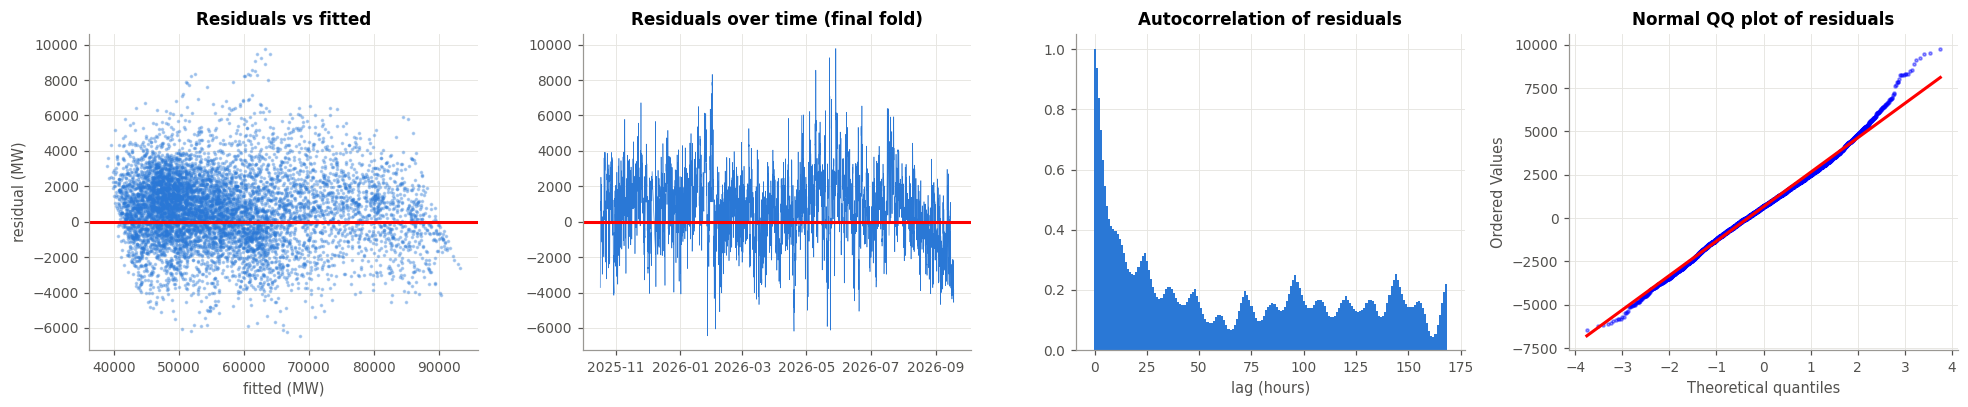

In [26]:
# ===== 8i. Are the model errors independent? =====
from statsmodels.tsa.stattools import acf
from statsmodels.stats.stattools import durbin_watson

tr, te = list(rolling_origin(len(d2)))[-1]
ridge.fit(d2.loc[tr, X_COLS], d2.loc[tr, "demand"])
fitted = ridge.predict(d2.loc[te, X_COLS])
resid  = d2.loc[te, "demand"].values - fitted

r = acf(resid, nlags=168, fft=True)
rho1 = r[1]
print(f"Durbin-Watson: {durbin_watson(resid):.2f}   (2 = independent, near 0 = strongly correlated)")
print("autocorrelation of errors at lag (hours):",
      {h: round(float(r[h]), 2) for h in [1, 2, 6, 12, 24, 48, 168]})
print(f"effective sample size: {len(resid):,} hours behave like about "
      f"{len(resid) * (1 - rho1) / (1 + rho1):,.0f} independent ones")

from scipy import stats
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
ax[0].scatter(fitted, resid, s=2, alpha=0.3)
ax[0].axhline(0, color="red"); ax[0].set_xlabel("fitted (MW)"); ax[0].set_ylabel("residual (MW)")
ax[0].set_title("Residuals vs fitted")
ax[1].plot(d2.loc[te, "ts"].values, resid, lw=0.4)
ax[1].axhline(0, color="red"); ax[1].set_title("Residuals over time (final fold)")
ax[2].bar(range(len(r)), r, width=1.0)
ax[2].set_xlabel("lag (hours)"); ax[2].set_title("Autocorrelation of residuals")
stats.probplot(resid, dist="norm", plot=ax[3])
ax[3].get_lines()[0].set(markersize=2, alpha=0.4); ax[3].set_title("Normal QQ plot of residuals")
plt.tight_layout(); plt.show()

**How to read it.** High lag-1 autocorrelation means the textbook SE formula and a normal bootstrap
both understate uncertainty: 8,000 correlated hours carry far less information than 8,000
independent observations. That is why 8j resamples whole weeks instead of single hours.

**What it shows.** Durbin-Watson is 0.11 and lag-1 autocorrelation 0.94: about 8,000 test hours carry
roughly as much information as 260 independent ones. The QQ plot shows heavier tails than a normal
distribution, mostly on extreme heat days.

### 8j. How sure are we? Block bootstrap confidence intervals

The bootstrap estimates a standard error when no clean formula applies. One change here: we resample
**whole weeks**, not single hours, so the correlation inside each week is kept.

1. Hourly bootstrap vs weekly block bootstrap SE for 2025, to show why blocks matter
2. A 95% CI for the cooling response in every year
3. The real test: is the 2023 to 2025 average different from 2019 to 2021? If the CI of the
   difference excludes zero, the change is real and not noise

2025 cool %/C  SE, hourly resampling: 0.029   SE, weekly blocks: 0.169   (5.9x wider)

      cool_pct_per_C  ci_low  ci_high
2019           5.834   5.575    6.019
2020           5.135   4.823    5.412
2021           5.729   5.304    6.117
2022           5.282   4.952    5.533
2023           5.032   4.803    5.222
2024           4.951   4.522    5.257
2025           4.611   4.223    4.909
2026           4.908   4.660    5.101

late minus early, cool %/C: -0.701   95% CI [-0.958, -0.454]   -> significant


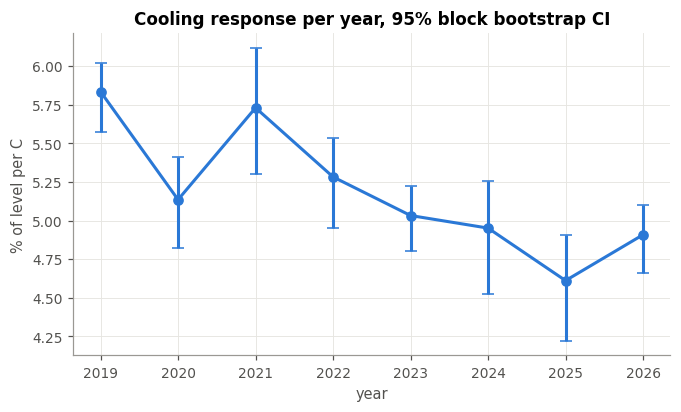

In [27]:
# ===== 8j. How sure are we? Block bootstrap confidence intervals =====
rng = np.random.default_rng(1)
B = 300

def block_boot(g, stat, B=B, block="W"):
    # resample whole weeks (block="W") or single hours (block=None) with replacement
    if block is None:
        groups = [np.array([i]) for i in range(len(g))]
    else:
        keys = g["ts"].dt.tz_convert("US/Central").dt.tz_localize(None).dt.to_period(block).astype(str).values
        groups = [np.flatnonzero(keys == k) for k in pd.unique(keys)]
    out = np.empty(B)
    for b in range(B):
        pick = rng.integers(0, len(groups), len(groups))
        idx = np.concatenate([groups[i] for i in pick])
        out[b] = stat(g.iloc[idx])
    return out

cool = lambda g: weather_response(g)["cool_pct_per_C"]

# 1) why blocks: naive hourly resampling vs weekly blocks, one year
g25 = d2[d2["year"] == 2025]
se_iid   = block_boot(g25, cool, B=200, block=None).std(ddof=1)
se_block = block_boot(g25, cool, B=200).std(ddof=1)
print(f"2025 cool %/C  SE, hourly resampling: {se_iid:.3f}   SE, weekly blocks: {se_block:.3f}"
      f"   ({se_block / se_iid:.1f}x wider)\n")

# 2) 95% CI per year
boots = {}
for yr, g in d2.groupby("year"):
    boots[yr] = block_boot(g, cool)
ci = pd.DataFrame({"cool_pct_per_C": wr["cool_pct_per_C"],
                   "ci_low":  {y: np.percentile(v, 2.5)  for y, v in boots.items()},
                   "ci_high": {y: np.percentile(v, 97.5) for y, v in boots.items()}})
print(ci.round(3).to_string())

# 3) the test: early era vs late era
early, late = [2019, 2020, 2021], [2023, 2024, 2025]
diff = np.mean([boots[y] for y in late], axis=0) - np.mean([boots[y] for y in early], axis=0)
point = wr.loc[late, "cool_pct_per_C"].mean() - wr.loc[early, "cool_pct_per_C"].mean()
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"\nlate minus early, cool %/C: {point:+.3f}   95% CI [{lo:+.3f}, {hi:+.3f}]"
      f"   -> {'significant' if (lo > 0 or hi < 0) else 'not significant'}")

plt.figure(figsize=(7, 3.8))
plt.errorbar(ci.index, ci["cool_pct_per_C"],
             yerr=[ci["cool_pct_per_C"] - ci["ci_low"], ci["ci_high"] - ci["cool_pct_per_C"]],
             fmt="o-", capsize=4)
plt.xlabel("year"); plt.ylabel("% of level per C")
plt.title("Cooling response per year, 95% block bootstrap CI"); plt.show()

**How to read it.** The SE ratio in the first line is how much a naive bootstrap would have
overstated our confidence. The last line is the answer to H3 for the whole of ERCOT.

**What it shows.** Weekly blocks give a standard error 5.9x wider than hourly resampling. Even with
the wider intervals, the late era (2023 to 2025) is 0.70 points below the early era (2019 to 2021), 95%
CI [-0.96, -0.45]. The drop in weather response is real, not noise.

### 8k. Which zones stopped following the weather?

8h treats Texas as one system. EIA also publishes demand for each of the 8 weather zones, and we
have each zone's own temperature. We repeat 8h per zone and per year, and add the daily min/max
ratio from Section 3 per zone.

If large loads drive the change, Far West (FWES) should show falling R2 and cooling response and a
ratio moving toward 1, while Houston (COAS) and Dallas (NCEN) stay weather-shaped. This is the
closest we can get to attribution without metered data by customer type.

In [28]:
# ===== 8k. Which zones stopped following the weather? =====
zd = (sub.dropna(subset=["ts"])
         .groupby(["ts", "Sub-Region"])["Demand (MW)"].sum().unstack())
zp = feat.set_index("ts")[[f"temperature_2m_{z}" for z in ZONES] + YR_COLS[2:]].join(zd, how="inner")
zp["year"] = zp.index.tz_convert("US/Central").year

R2, COOL, FLAT = {}, {}, {}
for z in ZONES:
    g = zp[[z, f"temperature_2m_{z}"] + YR_COLS[2:] + ["year"]].dropna()
    g = g[g[z] > 0].copy()
    g["cdh_z"] = (g[f"temperature_2m_{z}"] - 18.5).clip(lower=0)
    g["hdh_z"] = (18.5 - g[f"temperature_2m_{z}"]).clip(lower=0)
    res = {yr: weather_response(gy, y=z, cdh="cdh_z", hdh="hdh_z") for yr, gy in g.groupby("year")}
    R2[z]   = {yr: v["R2"] for yr, v in res.items()}
    COOL[z] = {yr: v["cool_pct_per_C"] for yr, v in res.items()}
    day = g[z].groupby(g.index.tz_convert("US/Central").date).agg(["min", "max"])
    day["year"] = pd.to_datetime(day.index).year
    FLAT[z] = (day["min"] / day["max"]).groupby(day["year"]).mean().to_dict()

for title, tab in [("R2 of weather + calendar, by zone (rows) and year", R2),
                   ("Cooling response, % of zone level per C", COOL),
                   ("Daily min/max ratio (1 = perfectly flat)", FLAT)]:
    print(f"\n{title}")
    print(pd.DataFrame(tab).T.round(2).to_string())


R2 of weather + calendar, by zone (rows) and year
      2019  2020  2021  2022  2023  2024  2025  2026
COAS  0.92  0.89  0.86  0.88  0.92  0.82  0.88  0.91
EAST  0.90  0.85  0.84  0.85  0.87  0.82  0.76  0.85
FWES  0.65  0.50  0.34  0.14  0.17  0.12  0.21  0.13
NRTH  0.90  0.84  0.78  0.82  0.75  0.78  0.58  0.78
NCEN  0.92  0.88  0.86  0.88  0.90  0.88  0.85  0.91
SOUT  0.91  0.88  0.87  0.85  0.90  0.88  0.84  0.90
SCEN  0.91  0.88  0.84  0.87  0.91  0.86  0.84  0.88
WEST  0.78  0.65  0.65  0.74  0.76  0.75  0.63  0.78

Cooling response, % of zone level per C
      2019  2020  2021  2022  2023  2024  2025  2026
COAS  5.92  5.06  5.85  5.21  5.30  5.45  4.88  5.34
EAST  5.71  5.96  5.92  5.84  6.26  6.17  5.72  6.04
FWES  0.95  0.94  0.82  0.61  0.48  0.30  0.19  0.21
NRTH  4.59  4.69  6.94  4.98  4.87  3.59  3.56  2.18
NCEN  7.23  6.82  7.32  6.90  6.64  6.79  6.08  6.75
SOUT  7.47  6.49  6.95  6.79  6.32  5.72  5.40  6.02
SCEN  7.06  6.69  7.02  6.32  5.96  6.18  5.83  6.33
WEST  3

**Chart.** Darker = higher. Read the FWES row against the COAS and NCEN rows.

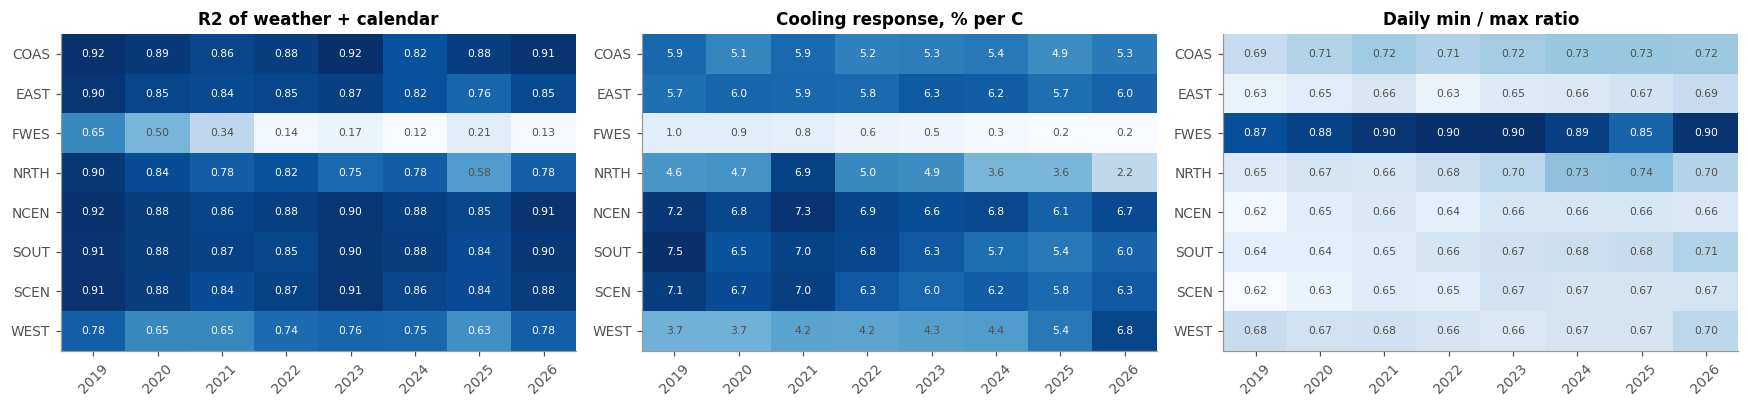

In [29]:
# ===== Chart: zone by year heatmaps =====
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, (title, tab, fmt) in zip(ax, [("R2 of weather + calendar", R2, "{:.2f}"),
                                     ("Cooling response, % per C", COOL, "{:.1f}"),
                                     ("Daily min / max ratio", FLAT, "{:.2f}")]):
    M = pd.DataFrame(tab).T
    im = a.imshow(M.values, cmap="Blues", aspect="auto")
    a.set_xticks(range(M.shape[1]), M.columns, rotation=45); a.set_yticks(range(M.shape[0]), M.index)
    a.grid(False); a.set_title(title)
    lo, hi = np.nanmin(M.values), np.nanmax(M.values)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            a.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                   color="white" if (v - lo) / (hi - lo + 1e-9) > 0.6 else INK)
plt.tight_layout(); plt.show()

**How to read it.** Read across each row. A zone whose R2 and cooling response fall while its ratio
climbs is a zone where always-on load is taking over.

**What it shows.** Far West is the outlier: R2 falls from 0.65 to 0.21 and cooling response from 0.95%
to 0.19% per degree. North weakens too (R2 0.90 to 0.58 in 2025). Houston, Dallas, Austin and Corpus
Christi stay between 0.82 and 0.92 every year. Far West was already flat (ratio near 0.9), which fits
large industrial load.

---
# 9. Regularisation, bias-variance and non-linear models

Section 8 found that OLS, Ridge and Lasso tie. This section shows why, tests how
regularisation and model flexibility behave on this data and then checks whether non-linear models
do better.

### 9a. Multicollinearity: how badly do our features overlap?

VIF = 1 / (1 - R2_j), where R2_j is how well all the other features predict feature j. Above 10 is a
warning, above 100 is severe.

1. One exact dependency: `temp = 18.5 + cdh - hdh` in every row, so OLS cannot separate those three
   coefficients at all (collinearity inflates the standard error of coefficients).
2. What that does in practice: refit OLS and Ridge on each of the 5 folds and measure how much each
   coefficient jumps around between folds.

In [30]:
# ===== 9a. Multicollinearity: variance inflation factors =====
# VIF_j = 1 / (1 - R2_j), where R2_j comes from regressing feature j on all the others.
# The diagonal of the inverse correlation matrix gives every VIF at once.
corr = np.corrcoef(d2[X_COLS].values, rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(corr)), index=X_COLS).sort_values(ascending=False)
show = vif.apply(lambda v: ">10,000" if v > 1e4 else f"{v:,.1f}")
print("15 highest VIFs (above 10 is a warning sign, above 100 is severe):")
print(show.head(15).to_string())
print(f"\nfeatures with VIF > 10: {(vif > 10).sum()} of {len(vif)}")

# the exact dependency: temp = 18.5 + cdh - hdh, every single hour
gap = (d2["temp"] - (18.5 + d2["cdh"] - d2["hdh"])).abs().max()
print(f"max |temp - (18.5 + cdh - hdh)| = {gap:.2e}  -> perfectly collinear")

# what collinearity does to coefficients: refit OLS and Ridge on each fold, compare stability
from sklearn.linear_model import Ridge
coefs = {"OLS": [], "Ridge": []}
for tr, te in rolling_origin(len(d2)):
    sc = StandardScaler().fit(d2.loc[tr, X_COLS])
    Xt = sc.transform(d2.loc[tr, X_COLS])
    coefs["OLS"].append(LinearRegression().fit(Xt, d2.loc[tr, "demand"]).coef_)
    coefs["Ridge"].append(Ridge(alpha=1000).fit(Xt, d2.loc[tr, "demand"]).coef_)
stab = pd.DataFrame({k: np.std(v, axis=0) for k, v in coefs.items()}, index=X_COLS)
top = vif.index[:8]
print("\nstd of each standardised coefficient across the 5 folds (MW per 1 SD), most collinear features:")
print(stab.loc[top].round(0).to_string())
print(f"\nmedian std across all features   OLS {stab['OLS'].median():,.0f}   Ridge {stab['Ridge'].median():,.0f}")

15 highest VIFs (above 10 is a warning sign, above 100 is severe):
temp_sq              153.2
month                141.6
doy                  140.2
cdh                   58.5
demand_rmean24        46.5
demand_rmean168       41.1
demand_lag24          31.8
cdh_24h               30.0
temp                  29.1
demand_lag48          23.0
temp_x_hour           20.8
demand_lag168         14.6
net_load_rmean168     13.7
hour                  12.7
hdh_24h               12.4

features with VIF > 10: 18 of 39
max |temp - (18.5 + cdh - hdh)| = 3.55e-15  -> perfectly collinear

std of each standardised coefficient across the 5 folds (MW per 1 SD), most collinear features:
                    OLS  Ridge
temp_sq          1057.0  439.0
month             337.0   57.0
doy               382.0   48.0
cdh               547.0  151.0
demand_rmean24    203.0   97.0
demand_rmean168   205.0  140.0
demand_lag24      202.0  340.0
cdh_24h           222.0  100.0

median std across all features   OLS 83   Ridge 57

**Chart.** Left: red bars are severe (VIF above 100). Right: shorter blue bars mean Ridge holds the coefficient steadier than OLS.

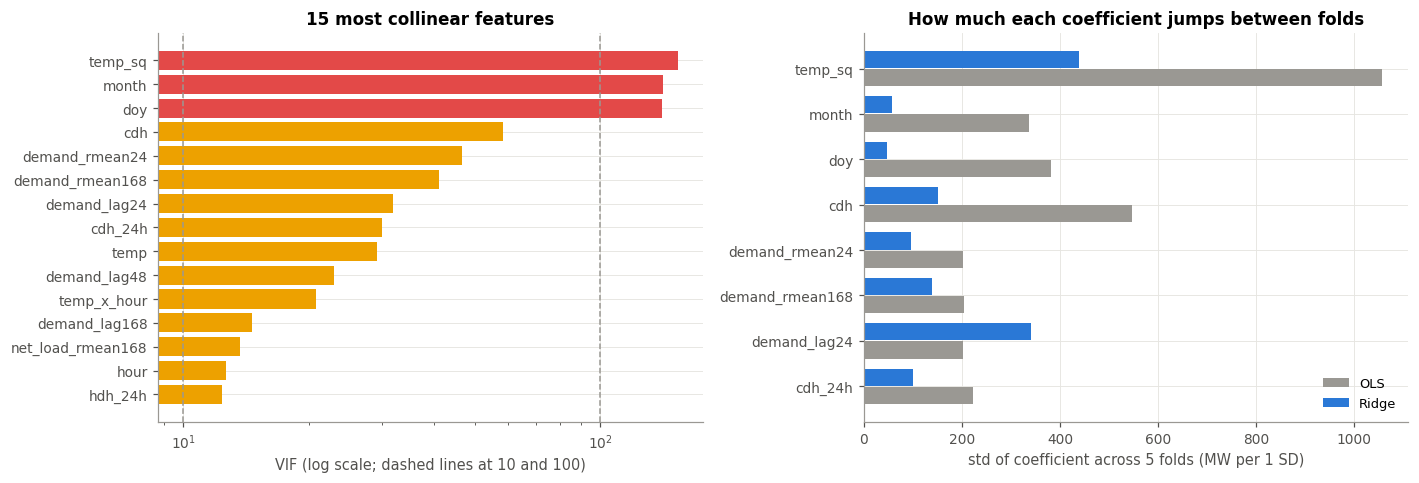

In [31]:
# ===== Chart: collinearity and what Ridge does about it =====
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
v = vif.head(15).iloc[::-1].clip(upper=1e5)
ax[0].barh(v.index, v.values, color=[RED if x > 100 else YELLOW if x > 10 else BLUE for x in v.values])
ax[0].set_xscale("log"); ax[0].axvline(10, color=GREY, ls="--", lw=1); ax[0].axvline(100, color=GREY, ls="--", lw=1)
ax[0].set_xlabel("VIF (log scale; dashed lines at 10 and 100)"); ax[0].set_title("15 most collinear features")
s8 = stab.loc[top]
yy_ = np.arange(len(s8))
ax[1].barh(yy_ + 0.2, s8["OLS"], 0.38, color=GREY, label="OLS")
ax[1].barh(yy_ - 0.2, s8["Ridge"], 0.38, color=BLUE, label="Ridge")
ax[1].set_yticks(yy_, s8.index); ax[1].invert_yaxis()
ax[1].set_xlabel("std of coefficient across 5 folds (MW per 1 SD)")
ax[1].set_title("How much each coefficient jumps between folds"); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read it.** If Ridge keeps the collinear coefficients much steadier than OLS while prediction
error stays the same, that is shrinkage at work: lowers variance for a small
increase in bias.

**What it shows.** 18 of 39 features have VIF above 10. Across folds, OLS coefficients swing much more
than Ridge ones (temp squared 1,057 vs 439 MW, month 337 vs 57), with the same prediction error.

### 9b. Does Lasso earn its keep when the features multiply?

With 39 features and about 66,000 rows the penalty had nothing to do. Here we build about 295
features: the 39, raw weather for all 8 zones (48), zone cooling and heating degree hours (16) and
zone cooling separately for every hour of the day (192).

Lambda is chosen by time-series CV. Two plots: CV error against lambda, and the
coefficient path. We also count which zones' weather terms Lasso keeps.

wide feature set: 295 features
fit in 35s   chosen alpha 17.36

final fold nMAE   Ridge, 39 features: 2.83%   Ridge, 295 features: 2.74%   Lasso, 295 features: 2.82%
Lasso kept 84 of 295 features

zone weather terms kept, by zone:
COAS     5
EAST     6
FWES    11
NRTH     3
NCEN     2
SOUT    22
SCEN     8
WEST     3


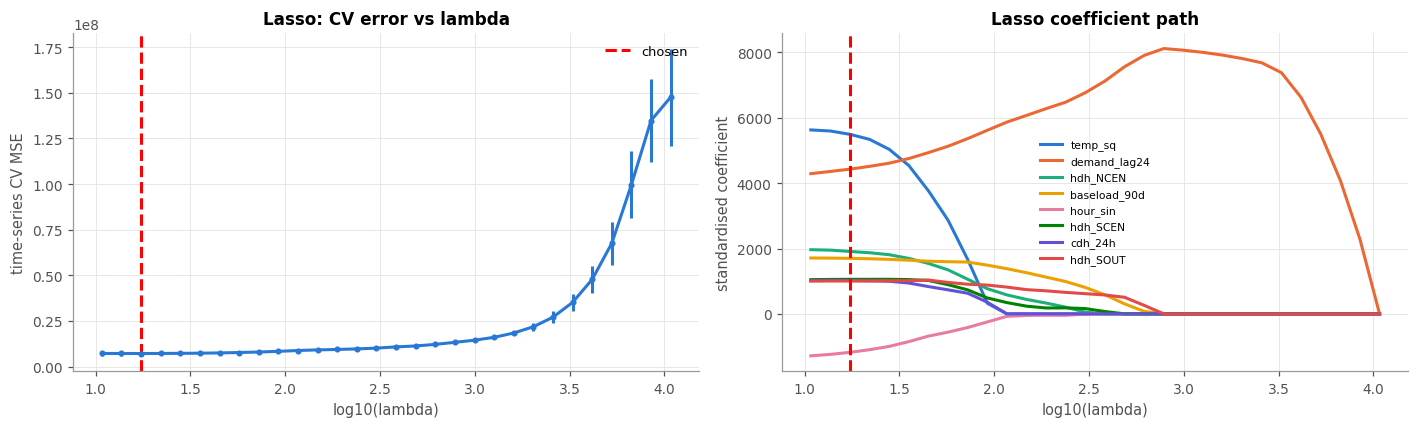

In [32]:
# ===== 9b. Lasso on a wide feature set (about 300 features) =====
import time
from sklearn.linear_model import lasso_path
ZRAW = [f"{v}_{z}" for v in ["temperature_2m", "dew_point_2m", "relative_humidity_2m",
                              "wind_speed_10m", "cloud_cover", "shortwave_radiation"] for z in ZONES]
extra = {}
for z in ZONES:
    t = d2[f"temperature_2m_{z}"]
    extra[f"cdh_{z}"] = (t - 18.5).clip(lower=0)
    extra[f"hdh_{z}"] = (18.5 - t).clip(lower=0)
    for h in range(24):                                   # zone cooling, separately for each hour
        extra[f"cdh_{z}_h{h:02d}"] = extra[f"cdh_{z}"] * (d2["hour"] == h)
wide = pd.concat([d2[X_COLS + ZRAW], pd.DataFrame(extra)], axis=1)
WIDE = list(wide.columns)
print(f"wide feature set: {len(WIDE)} features")

tr, te = list(rolling_origin(len(d2)))[-1]
t0 = time.time()
lasso_w = make_pipeline(StandardScaler(),
                        LassoCV(n_alphas=30, cv=TSCV, max_iter=3000, n_jobs=-1, random_state=0))
lasso_w.fit(wide.loc[tr], d2.loc[tr, "demand"])
lcv = lasso_w[-1]
print(f"fit in {time.time() - t0:.0f}s   chosen alpha {lcv.alpha_:.2f}")

def nmae(model, X):
    model.fit(X.loc[tr], d2.loc[tr, "demand"])
    p = model.predict(X.loc[te]); yt = d2.loc[te, "demand"].values
    return mean_absolute_error(yt, p) / yt.mean() * 100

yt = d2.loc[te, "demand"].values
p_l = lasso_w.predict(wide.loc[te])
print(f"\nfinal fold nMAE   Ridge, 39 features: {nmae(ridge, d2[X_COLS]):.2f}%"
      f"   Ridge, {len(WIDE)} features: {nmae(ridge, wide):.2f}%"
      f"   Lasso, {len(WIDE)} features: {mean_absolute_error(yt, p_l) / yt.mean() * 100:.2f}%")

coef = pd.Series(lcv.coef_, index=WIDE)
print(f"Lasso kept {(coef != 0).sum()} of {len(WIDE)} features")
print("\nzone weather terms kept, by zone:")
print(pd.Series({z: int((coef[[c for c in WIDE if c.endswith(z) or f"_{z}_h" in c]] != 0).sum())
                 for z in ZONES}).to_string())

# CV error against lambda, the same picture as PS3 6.8(e)
mse, a = lcv.mse_path_.mean(axis=1), lcv.alphas_
se = lcv.mse_path_.std(axis=1) / np.sqrt(lcv.mse_path_.shape[1])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].errorbar(np.log10(a), mse, yerr=se, fmt="o-", ms=3)
ax[0].axvline(np.log10(lcv.alpha_), color="red", ls="--", label="chosen")
ax[0].set_xlabel("log10(lambda)"); ax[0].set_ylabel("time-series CV MSE"); ax[0].legend()
ax[0].set_title("Lasso: CV error vs lambda")
# coefficient path for the 8 largest surviving coefficients
_, path, _ = lasso_path(StandardScaler().fit_transform(wide.loc[tr]),
                          d2.loc[tr, "demand"].values, alphas=a)
for j in coef.abs().sort_values(ascending=False).index[:8]:
    ax[1].plot(np.log10(a), path[WIDE.index(j)], label=j)
ax[1].axvline(np.log10(lcv.alpha_), color="red", ls="--")
ax[1].set_xlabel("log10(lambda)"); ax[1].set_ylabel("standardised coefficient")
ax[1].set_title("Lasso coefficient path"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**What it shows.** Ridge on 295 features is the best single model here (2.74% vs 2.83% on 39). Lasso
keeps 84 of 295 features and matches it at 2.82%. Zone weather columns are strongly correlated with
each other, so which zone's column Lasso keeps is unstable and should not be read as zone importance.
Section 8k is the zone-level answer.

### 9c. The bias-variance trade-off on real data

How does model flexibility change training and test error? KNN makes it visible.
K = 1 is the most flexible model (it memorises every training hour) and K = 500 the least (it
averages 500 neighbours).

Expected: training error falls all the way to zero as K shrinks, while test error is U-shaped. The
bottom of the U is the best balance. Training error is measured on a random 8,000-hour sample to
keep it fast.

  K  flexibility_1_over_K  train_nMAE  test_nMAE
  1                  1.00        0.00       5.94
  2                  0.50        1.66       5.80
  5                  0.20        2.18       5.78
 10                  0.10        2.83       5.97
 20                  0.05        3.29       6.36
 50                  0.02        3.88       7.10
100                  0.01        4.34       7.70
200                  0.00        4.75       8.28
500                  0.00        5.35       9.31

best K = 5, test nMAE 5.78%   (Ridge on the same fold: see 8d)


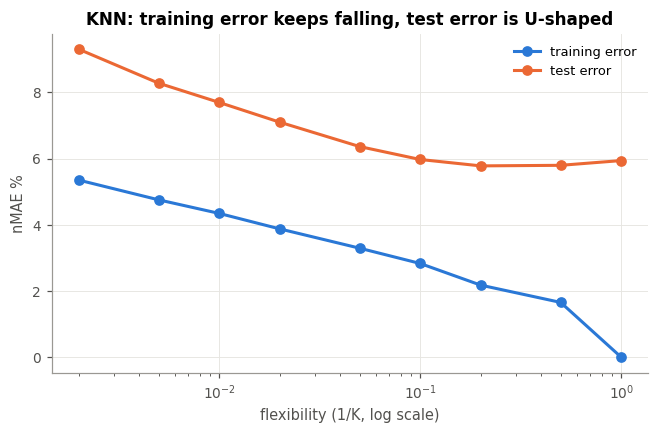

In [33]:
# ===== 9c. Bias-variance trade-off on real data: KNN flexibility curve =====
from sklearn.neighbors import KNeighborsRegressor
KNN_COLS = ["temp", "cdh", "hdh", "hour_sin", "hour_cos", "dow_sin", "dow_cos",
            "is_weekend", "is_holiday", "doy_sin", "doy_cos", "demand_lag24", "demand_lag168"]
tr, te = list(rolling_origin(len(d2)))[-1]
sc = StandardScaler().fit(d2.loc[tr, KNN_COLS])
Xtr, Xte = sc.transform(d2.loc[tr, KNN_COLS]), sc.transform(d2.loc[te, KNN_COLS])
ytr, yte = d2.loc[tr, "demand"].values, d2.loc[te, "demand"].values
sub_tr = np.random.default_rng(0).choice(len(Xtr), 8000, replace=False)   # train error on a sample

rows = []
for k in [1, 2, 5, 10, 20, 50, 100, 200, 500]:
    knn = KNeighborsRegressor(n_neighbors=k, n_jobs=-1).fit(Xtr, ytr)
    rows.append({"K": k, "flexibility_1_over_K": 1 / k,
                 "train_nMAE": mean_absolute_error(ytr[sub_tr], knn.predict(Xtr[sub_tr])) / ytr.mean() * 100,
                 "test_nMAE":  mean_absolute_error(yte, knn.predict(Xte)) / yte.mean() * 100})
kc = pd.DataFrame(rows)
print(kc.round(2).to_string(index=False))
best = kc.loc[kc["test_nMAE"].idxmin()]
print(f"\nbest K = {int(best['K'])}, test nMAE {best['test_nMAE']:.2f}%   (Ridge on the same fold: see 8d)")

plt.figure(figsize=(7, 4))
plt.plot(kc["flexibility_1_over_K"], kc["train_nMAE"], "o-", label="training error")
plt.plot(kc["flexibility_1_over_K"], kc["test_nMAE"], "o-", label="test error")
plt.xscale("log"); plt.xlabel("flexibility (1/K, log scale)"); plt.ylabel("nMAE %")
plt.title("KNN: training error keeps falling, test error is U-shaped"); plt.legend(); plt.show()

**How to read it.** The left side of the U is high variance (overfitting), the right side is high
bias. Compare the best KNN with Ridge on the same fold (8d, fold 4). KNN also cannot predict above
the highest load it has seen, the same limit trees hit in 9f.

**What it shows.** Training error falls to 0 at K = 1. Test error bottoms out at K = 5 (5.78%) and rises
to 9.3% at K = 500. Even the best KNN is about twice Ridge's error in this fold, because KNN can only
average past hours it has seen.

### 9d. Gradient boosting vs Ridge

In [34]:
# ===== 9d. Gradient boosting vs Ridge on demand =====
from sklearn.ensemble import HistGradientBoostingRegressor
import time

MODELS_NL = {
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TSCV)),
    "HGB":   HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=0),
}

rows = []
for name, model in MODELS_NL.items():
    t0, folds = time.time(), []
    for tr, te in rolling_origin(len(d2)):
        model.fit(d2.loc[tr, X_COLS], d2.loc[tr, "demand"])
        p, yt = model.predict(d2.loc[te, X_COLS]), d2.loc[te, "demand"].values
        folds.append(mean_absolute_error(yt, p) / yt.mean() * 100)
    rows.append({"model": name, "nMAE_pct": round(np.mean(folds), 2),
                 "per_fold": [round(f, 1) for f in folds]})
    print(f"{name:<6} {time.time()-t0:5.0f}s")

print("\n", pd.DataFrame(rows).to_string(index=False))
rows_nl = rows          # kept for the 9f chart

Ridge     14s
HGB       33s

 model  nMAE_pct                  per_fold
Ridge      3.18 [3.2, 3.5, 3.4, 3.0, 2.8]
  HGB      3.32 [2.9, 4.3, 3.1, 3.3, 3.0]


### 9e. Random forest

40 trees with leaf size 50, so it finishes in about two minutes on free Colab.

In [35]:
from sklearn.ensemble import RandomForestRegressor
import time
t0 = time.time()
rf = RandomForestRegressor(n_estimators=40, min_samples_leaf=50, max_features=0.4,
                           n_jobs=-1, random_state=0)
folds = []
for tr, te in rolling_origin(len(d2)):
    rf.fit(d2.loc[tr, X_COLS], d2.loc[tr, "demand"])
    p, yt = rf.predict(d2.loc[te, X_COLS]), d2.loc[te, "demand"].values
    folds.append(mean_absolute_error(yt, p) / yt.mean() * 100)
    print(f"  fold done, {time.time()-t0:.0f}s elapsed")
print(f"RF nMAE {np.mean(folds):.2f}%  per fold {[round(f,1) for f in folds]}")
rf_folds = folds        # kept for the 9f chart

  fold done, 10s elapsed
  fold done, 23s elapsed
  fold done, 40s elapsed
  fold done, 59s elapsed
  fold done, 84s elapsed
RF nMAE 4.21%  per fold [np.float64(3.9), np.float64(4.6), np.float64(4.5), np.float64(4.2), np.float64(3.9)]


### 9f. Why the linear model wins: extrapolation

We compare Ridge and RF on all test hours and on the hottest 5% of hours only.

In [36]:
for name, mdl in [("Ridge", make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TSCV))),
                  ("RF", rf)]:
    tr, te = list(rolling_origin(len(d2)))[-1]
    mdl.fit(d2.loc[tr, X_COLS], d2.loc[tr, "demand"])
    p, yt = mdl.predict(d2.loc[te, X_COLS]), d2.loc[te, "demand"].values
    hi = yt > np.percentile(yt, 95)
    print(f"{name:<6} all hours {mean_absolute_error(yt,p):>7,.0f} MW | "
          f"top-5% hours {mean_absolute_error(yt[hi],p[hi]):>7,.0f} MW | "
          f"train max {d2.loc[tr,'demand'].max():>7,.0f} | test max {yt.max():>7,.0f}")

Ridge  all hours   1,635 MW | top-5% hours   1,567 MW | train max  85,544 | test max  91,075
RF     all hours   2,237 MW | top-5% hours   5,240 MW | train max  85,544 | test max  91,075


**Chart.** Left: mean error of the three models. Right: the days with the highest load in the test window, with the training maximum as a red dashed line.

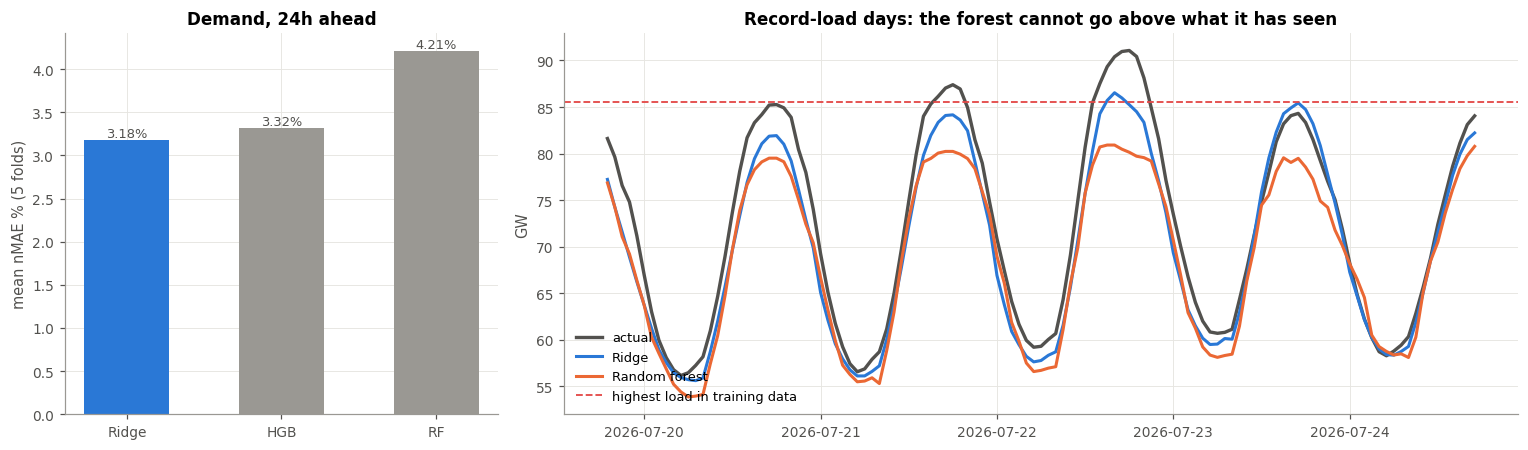

In [37]:
# ===== Chart: trees hit a ceiling, the linear model does not =====
nl = {r["model"]: r["nMAE_pct"] for r in rows_nl}
nl["RF"] = np.mean(rf_folds)
tr, te = list(rolling_origin(len(d2)))[-1]
rdg = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TSCV)).fit(d2.loc[tr, X_COLS], d2.loc[tr, "demand"])
w = d2.loc[te, ["ts", "demand"]].copy()
w["Ridge"], w["RF"] = rdg.predict(d2.loc[te, X_COLS]), rf.predict(d2.loc[te, X_COLS])
peak = w.loc[w["demand"].idxmax(), "ts"]
wk = w[(w["ts"] > peak - pd.Timedelta(days=3)) & (w["ts"] < peak + pd.Timedelta(days=2))]
x = wk["ts"].dt.tz_convert("US/Central")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
bars = ax[0].bar(nl.keys(), nl.values(), color=[BLUE if k == "Ridge" else GREY for k in nl], width=0.55)
ax[0].bar_label(bars, fmt="%.2f%%", fontsize=8.5, color=INK)
ax[0].set_ylabel("mean nMAE % (5 folds)"); ax[0].set_title("Demand, 24h ahead")
ax[1].plot(x, wk["demand"] / 1000, color=INK, lw=2.2, label="actual")
ax[1].plot(x, wk["Ridge"] / 1000, color=BLUE, label="Ridge")
ax[1].plot(x, wk["RF"] / 1000, color=ORANGE, label="Random forest")
ax[1].axhline(d2.loc[tr, "demand"].max() / 1000, color=RED, ls="--", lw=1.2, label="highest load in training data")
ax[1].set_ylabel("GW"); ax[1].set_title("Record-load days: the forest cannot go above what it has seen")
ax[1].legend(loc="lower left"); plt.tight_layout(); plt.show()

### 9g. Which feature groups matter, early era vs late era?

This is the H3 test from the model's point of view. We train Ridge on 2019 to 2021 and test on 2022,
then train on 2023 to 2025 and test on 2026. For each era we shuffle one feature group at a time
(calendar, weather, load lags, baseload floor) and measure how much the error rises. A big rise means
the model leans on that group.

We shuffle whole groups because features inside a group overlap heavily (9a), so shuffling one column
at a time would understate every group.

In [38]:
# ===== 9g. Which feature groups matter, early era vs late era? =====
# Grouped permutation importance: shuffle a whole group of columns together and measure how much
# the test error rises. Grouping is needed because features inside a group are collinear (9a).
GROUPS = {
    "calendar": [c for c in X_COLS if c in ("hour", "dow", "month", "doy", "is_weekend", "is_holiday")
                 or c.endswith(("_sin", "_cos"))],
    "weather":  [c for c in X_COLS if c in ("temp", "dewpt", "wind", "cloud", "rad", "cdh", "hdh",
                 "temp_sq", "temp_x_hour", "wind_cubed", "cdh_24h", "hdh_24h")],
    "load lags": [c for c in X_COLS if "lag" in c or "rmean" in c or "rstd" in c],
    "baseload floor": ["baseload_90d"],
}
assert sum(len(v) for v in GROUPS.values()) == len(X_COLS), "every feature in exactly one group"

ERAS = {"early: train 2019-21, test 2022": ([2019, 2020, 2021], [2022]),
        "late: train 2023-25, test 2026":  ([2023, 2024, 2025], [2026])}
rng = np.random.default_rng(0)
imp = {}
for era, (tr_y, te_y) in ERAS.items():
    trd, ted = d2[d2["year"].isin(tr_y)], d2[d2["year"].isin(te_y)]
    mdl = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TSCV))
    for label, cols in [("full model", X_COLS), ("weather + calendar only", WX_ONLY)]:
        mdl.fit(trd[cols], trd["demand"])
        base = mean_absolute_error(ted["demand"], mdl.predict(ted[cols]))
        for g, gc in GROUPS.items():
            gc = [c for c in gc if c in cols]
            if not gc: continue
            rises = []
            for _ in range(5):
                Xp = ted[cols].copy()
                Xp[gc] = Xp[gc].values[rng.permutation(len(Xp))]
                rises.append(mean_absolute_error(ted["demand"], mdl.predict(Xp)) - base)
            imp[(era, label, g)] = np.mean(rises) / ted["demand"].mean() * 100
imp = pd.Series(imp).unstack(0).round(2)
print("rise in nMAE (percentage points) when a feature group is shuffled")
print(imp.to_string())

rise in nMAE (percentage points) when a feature group is shuffled
                                        early: train 2019-21, test 2022  late: train 2023-25, test 2026
full model              baseload floor                             0.02                            0.36
                        calendar                                   1.84                            2.91
                        load lags                                  6.69                            6.91
                        weather                                   10.24                            8.78
weather + calendar only calendar                                   3.08                            3.18
                        weather                                   13.88                           11.64


**Chart.** Grey is the early era, blue the late era. If the weather bars shrink from grey to blue while the lag and floor bars grow, the model has shifted from weather to history as load became less weather-driven.

**What it shows.** Weather matters less in the late era: shuffling it raises error by 10.2 points
in the early era and 8.8 in the late era (13.9 vs 11.6 for the weather-only model). The calendar and
baseload floor matter more.

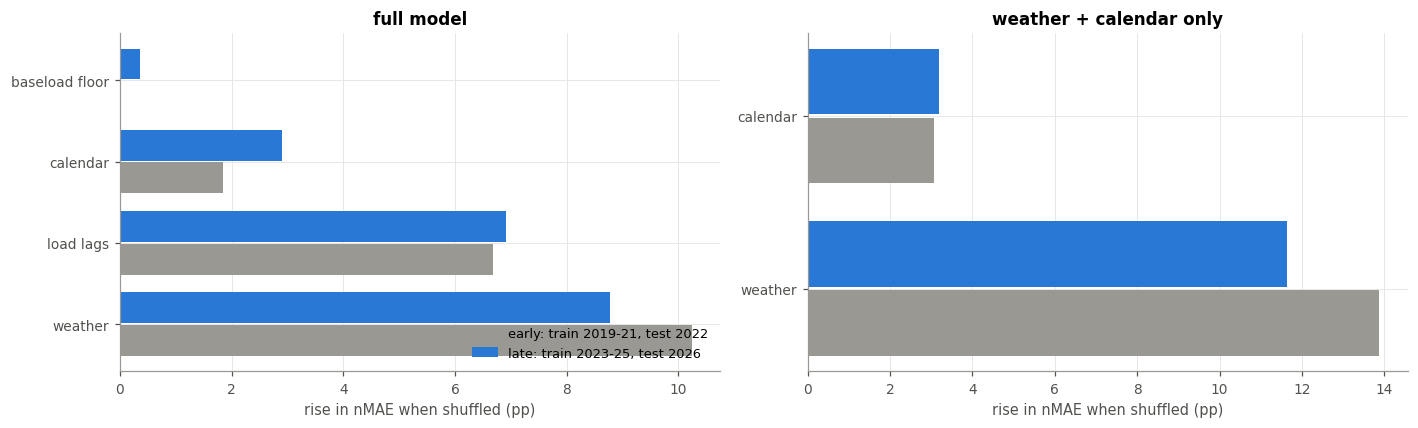

In [39]:
# ===== Chart: feature group importance by era =====
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, label in zip(ax, ["full model", "weather + calendar only"]):
    t_ = imp.xs(label, level=0)
    yy_ = np.arange(len(t_))
    for i, (era, col) in enumerate(zip(t_.columns, [GREY, BLUE])):
        a.barh(yy_ + (0.2 if i == 0 else -0.2), t_[era], 0.38, color=col, label=era)
    a.set_yticks(yy_, t_.index); a.invert_yaxis()
    a.set_xlabel("rise in nMAE when shuffled (pp)"); a.set_title(label)
ax[0].legend(loc="lower right"); plt.tight_layout(); plt.show()

### 9h. Does older history still help?

Previous projects show a learning curve: error against training size. For a system that is changing,
the better question is whether **old** data still helps. We keep the final test window fixed and train
on only the last 1, 2, 3 or 4 years, or on everything.

final-fold test nMAE % by how much history the model trains on
features      full model  weather + calendar only
train window                                     
last 1 yr           3.15                     4.33
last 2 yr           2.95                     5.90
last 3 yr           2.91                     7.84
last 4 yr           2.91                     9.57
all                 2.83                    13.54


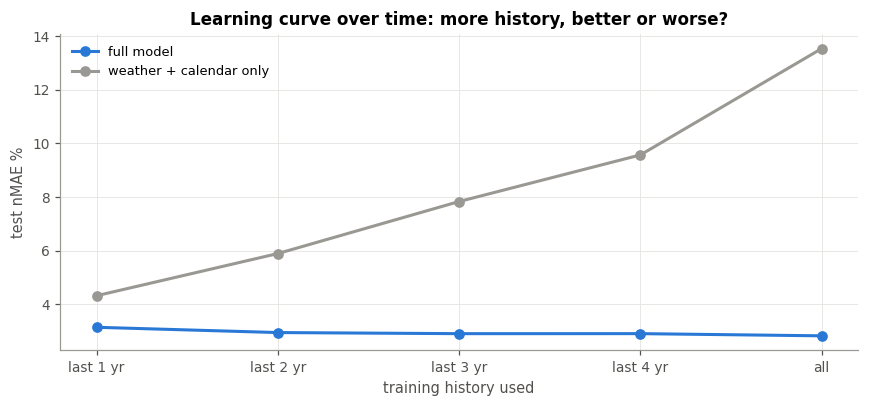

In [40]:
# ===== 9h. Does older history still help? Training-window length =====
tr, te = list(rolling_origin(len(d2)))[-1]
test_start = d2.loc[te[0], "ts"]
rows_w = []
for yrs in [1, 2, 3, 4, None]:
    keep_ = tr if yrs is None else tr[d2.loc[tr, "ts"] >= test_start - pd.Timedelta(days=365 * yrs)]
    for label, cols in [("full model", X_COLS), ("weather + calendar only", WX_ONLY)]:
        ridge.fit(d2.loc[keep_, cols], d2.loc[keep_, "demand"])
        p, yt = ridge.predict(d2.loc[te, cols]), d2.loc[te, "demand"].values
        rows_w.append({"train window": "all" if yrs is None else f"last {yrs} yr", "features": label,
                       "train hours": len(keep_), "nMAE": mean_absolute_error(yt, p) / yt.mean() * 100})
win = pd.DataFrame(rows_w).pivot(index="train window", columns="features", values="nMAE")
win = win.loc[["last 1 yr", "last 2 yr", "last 3 yr", "last 4 yr", "all"]]
print("final-fold test nMAE % by how much history the model trains on")
print(win.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
for c, col in zip(win.columns, [BLUE, GREY]):
    ax.plot(win.index, win[c], "o-", color=col, label=c)
ax.set_ylabel("test nMAE %"); ax.set_xlabel("training history used")
ax.set_title("Learning curve over time: more history, better or worse?"); ax.legend()
plt.tight_layout(); plt.show()

**How to read it.** If the error rises when we add older years, the old relationship has gone stale, which is more evidence the system changed. If it keeps falling, older years still teach the model something useful.

**What it shows.** For the full model, more history helps a little (3.15% to 2.83%). For the
weather-only model, more history hurts badly (4.3% to 13.5%): the old weather-to-load mapping no longer
fits today's Texas.

Things that stand out:
- Ridge: about 1,590 MW on all hours and about the same on the hottest 5%.
- RF: about 2,240 MW overall but about 5,240 MW on the hottest 5%.
- The final test window peaks at 91,075 MW, the training data at 85,544 MW. A tree can only predict
  averages of values it has already seen, so it caps out below the new peaks. A linear model just
  extends the line.
- Hand-built terms (temp squared, temp by hour, degree hours) already give Ridge the curvature it
  needs. (F5)

---
# 10. Can stress hours be flagged 24 hours ahead?

### Why a fixed threshold does not work

First attempt: call the top 10%, 5% or 1% of all demand hours "stress" using one fixed line.

In [41]:
for pct in [90, 95, 99]:
    thr = d2["demand"].quantile(pct / 100)
    lab = (d2["demand"] > thr).astype(int)
    counts = [int(lab.iloc[te].sum()) for _, te in rolling_origin(len(d2))]
    print(f"top {100-pct:>2}%  threshold {thr:>7,.0f} MW  positives per fold: {counts}")

top 10%  threshold  67,214 MW  positives per fold: [737, 1113, 1077, 1445, 1588]
top  5%  threshold  73,184 MW  positives per fold: [270, 666, 518, 754, 1069]
top  1%  threshold  81,828 MW  positives per fold: [0, 129, 67, 28, 441]


With one fixed line, positives climb with growth (top 1%: 0 in fold 0, 441 in fold 4) simply because
later years have more load. A stress label has to move with the system, so 10a uses a trailing
one-year line instead.

### 10a. Stress labels

For every hour we look back over the past year (ending 24 hours earlier) and find the 95th
percentile. If this hour is above that line, it is a stress hour. Hours with less than 90 days of
history have no line yet, so they are dropped, not called "normal".

The primary label is on **net load**, as defined in the proposal, because net load is what actually
makes the grid tight. The demand label runs alongside for comparison.

In [42]:
# ===== 10a. Stress labels: trailing 365-day 95th percentile =====
dc = feat.dropna(subset=X_COLS + ["demand", "y_netload"]).reset_index(drop=True)

def stress_label(df, col, q):
    # threshold for hour t uses only hours up to t-24h (shift by time, not by rows)
    s   = df.set_index("ts")[col]
    thr = (s.shift(freq="24h").rolling("365D", min_periods=24 * 90).quantile(q)
             .reindex(s.index, method="ffill"))
    lab = (s > thr).astype(float).where(thr.notna())      # no threshold yet -> unknown, not 0
    return lab.values, thr.values

for col, lab in [("y_netload", "stress_nl"), ("demand", "stress_dm")]:
    dc[lab], dc[f"thr_{lab}"] = stress_label(dc, col, 0.95)

dc = dc.dropna(subset=["stress_nl", "stress_dm"]).reset_index(drop=True)
for lab in ["stress_nl", "stress_dm"]:
    dc[lab] = dc[lab].astype(int)
    print(f"{lab}  rate {dc[lab].mean() * 100:4.1f}%  positives per fold:",
          [int(dc[lab].iloc[te].sum()) for _, te in rolling_origin(len(dc))])

print("\nsensitivity, net load label:")
for q in [0.90, 0.99]:
    lab, _ = stress_label(dc, "y_netload", q)
    print(f"  q={q}: positives per fold",
          [int(np.nansum(lab[te])) for _, te in rolling_origin(len(dc))])

print("\nshare of net load stress hours by month:")
print((dc.groupby(dc["ts"].dt.tz_convert("US/Central").dt.month)["stress_nl"].sum()
         / dc["stress_nl"].sum() * 100).round(1).to_string())

stress_nl  rate  5.9%  positives per fold: [526, 640, 247, 437, 432]
stress_dm  rate  7.3%  positives per fold: [659, 717, 328, 548, 735]

sensitivity, net load label:
  q=0.9: positives per fold [995, 1010, 607, 850, 821]
  q=0.99: positives per fold [115, 233, 22, 102, 122]

share of net load stress hours by month:
ts
1      4.1
2      4.0
3      0.0
4      0.1
5      2.1
6     12.7
7     25.3
8     36.8
9     13.0
10     1.4
11     0.0
12     0.6


**Chart.** Left: when stress happens. Right: one summer with the moving 95th percentile line; orange dots are the hours labelled as stress.

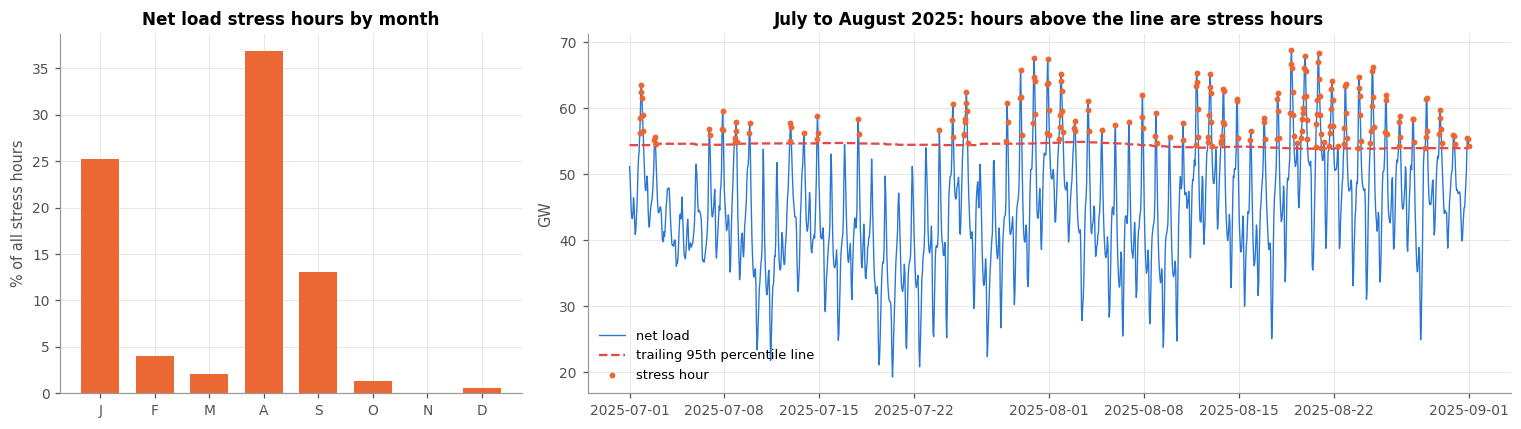

In [43]:
# ===== Chart: what a stress hour looks like =====
mo = dc.groupby(dc["ts"].dt.tz_convert("US/Central").dt.month)["stress_nl"].sum()
mo = mo.reindex(range(1, 13), fill_value=0) / mo.sum() * 100
yr_last = dc["ts"].dt.tz_convert("US/Central").dt.year.max() - 1
s = dc[(dc["ts"].dt.tz_convert("US/Central").dt.year == yr_last) &
       (dc["ts"].dt.tz_convert("US/Central").dt.month.isin([7, 8]))]
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(["J","F","M","A","M","J","J","A","S","O","N","D"], mo.values, color=ORANGE, width=0.7)
ax[0].set_ylabel("% of all stress hours"); ax[0].set_title("Net load stress hours by month")
x = s["ts"].dt.tz_convert("US/Central")
ax[1].plot(x, s["y_netload"] / 1000, color=BLUE, lw=0.9, label="net load")
ax[1].plot(x, s["thr_stress_nl"] / 1000, color=RED, lw=1.5, ls="--", label="trailing 95th percentile line")
hit = s["stress_nl"] == 1
ax[1].scatter(x[hit], s.loc[hit, "y_netload"] / 1000, s=8, color=ORANGE, zorder=3, label="stress hour")
ax[1].set_ylabel("GW"); ax[1].set_title(f"July to August {yr_last}: hours above the line are stress hours")
ax[1].legend(loc="lower left"); plt.tight_layout(); plt.show()

**Check.** Every fold needs at least about 50 positives. If the 99% row has a fold under 50, that is
why it stays a sensitivity check only.

### 10b. Stress classification

Five approaches try to flag stress hours 24 hours ahead. The first is the simple baseline: was this
hour stressed yesterday? Any model that cannot beat it is not useful.

- **Precision:** of the alarms raised, how many were real
- **Recall:** of the real stress hours, how many we caught
- **F1:** one number balancing the two
- **AUC-PR:** area under the precision-recall curve, the right summary when positives are rare.
  Random guessing scores the base rate.

stress_nl LogReg-L2       8s
stress_nl LogReg-L1      54s
stress_nl SVM-RBF        31s
stress_nl HGB            13s
stress_dm LogReg-L2       9s
stress_dm LogReg-L1      42s
stress_dm SVM-RBF        30s
stress_dm HGB            12s

mean over 5 rolling-origin folds (base_rate = AUC-PR of random guessing)
    label       model  precision  recall    F1  AUC_PR  base_rate
stress_nl Persistence      0.693   0.691 0.692   0.746      0.059
stress_nl   LogReg-L2      0.418   0.901 0.565   0.707      0.059
stress_nl   LogReg-L1      0.416   0.902 0.563   0.713      0.059
stress_nl     SVM-RBF      0.437   0.911 0.586   0.767      0.059
stress_nl         HGB      0.607   0.747 0.659   0.752      0.059
stress_dm Persistence      0.840   0.835 0.838   0.901      0.077
stress_dm   LogReg-L2      0.589   0.929 0.700   0.891      0.077
stress_dm   LogReg-L1      0.583   0.926 0.695   0.896      0.077
stress_dm     SVM-RBF      0.633   0.929 0.728   0.916      0.077
stress_dm         HGB      0.793  

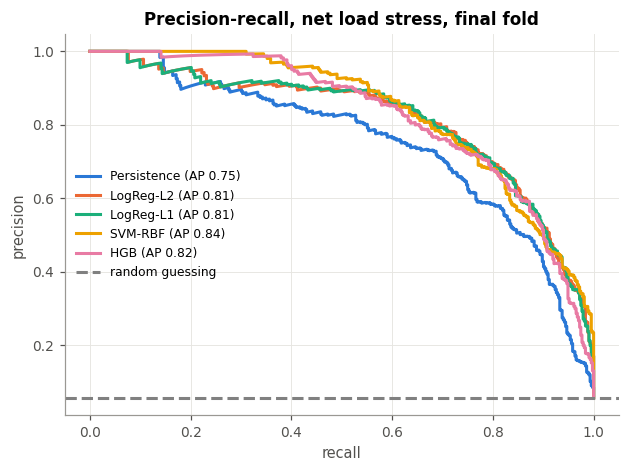

In [44]:
# ===== 10b. Stress classification: persistence + 4 models x 2 labels =====
import time
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, average_precision_score, precision_recall_curve)

CLF = {
    "LogReg-L2": make_pipeline(StandardScaler(),
                   LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced")),
    "LogReg-L1": make_pipeline(StandardScaler(),
                   LogisticRegression(C=0.1, penalty="l1", solver="liblinear",
                                      class_weight="balanced", random_state=0)),
    "SVM-RBF":   make_pipeline(StandardScaler(),
                   Nystroem(kernel="rbf", n_components=500, random_state=0),
                   LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=0)),
    "HGB":       HistGradientBoostingClassifier(max_iter=300, class_weight="balanced",
                                                random_state=0),
}

LABELS = {"stress_nl": ("net_load_lag24", "thr_stress_nl"),
          "stress_dm": ("demand_lag24",   "thr_stress_dm")}

def score_fold(yt, yhat, score):
    return dict(precision=precision_score(yt, yhat, zero_division=0),
                recall=recall_score(yt, yhat, zero_division=0),
                F1=f1_score(yt, yhat, zero_division=0),
                AUC_PR=average_precision_score(yt, score),
                base_rate=yt.mean())

folds = list(rolling_origin(len(dc)))
rows, last_cm, last_score = [], {}, {}

for lab, (lagcol, thrcol) in LABELS.items():
    # persistence: stressed if the same hour yesterday was above today's line
    res = []
    for k, (tr, te) in enumerate(folds):
        yt  = dc.loc[te, lab].values
        gap = (dc.loc[te, lagcol] - dc.loc[te, thrcol]).values
        res.append(score_fold(yt, (gap > 0).astype(int), gap))
        if k == len(folds) - 1:
            last_cm[(lab, "Persistence")] = confusion_matrix(yt, (gap > 0).astype(int))
            last_score[(lab, "Persistence")] = gap
    rows.append({"label": lab, "model": "Persistence", **pd.DataFrame(res).mean().to_dict()})

    for name, clf in CLF.items():
        t0, res = time.time(), []
        for k, (tr, te) in enumerate(folds):
            clf.fit(dc.loc[tr, X_COLS], dc.loc[tr, lab])
            yt    = dc.loc[te, lab].values
            yhat  = clf.predict(dc.loc[te, X_COLS])
            score = clf.decision_function(dc.loc[te, X_COLS])   # works for all four
            res.append(score_fold(yt, yhat, score))
            if k == len(folds) - 1:
                last_cm[(lab, name)] = confusion_matrix(yt, yhat)
                last_score[(lab, name)] = score
        rows.append({"label": lab, "model": name, **pd.DataFrame(res).mean().to_dict()})
        print(f"{lab:<10}{name:<12} {time.time() - t0:4.0f}s")

cls = pd.DataFrame(rows).round(3)
print("\nmean over 5 rolling-origin folds (base_rate = AUC-PR of random guessing)")
print(cls.to_string(index=False))

print("\nconfusion matrices, final fold, net load label   [[TN, FP], [FN, TP]]")
for (lab, name), cm in last_cm.items():
    if lab == "stress_nl":
        print(f"  {name:<12}", cm.tolist())

# precision-recall curves, final fold, net load label
yt_last = dc.loc[folds[-1][1], "stress_nl"].values
plt.figure(figsize=(6.5, 4.5))
for (lab, name), s in last_score.items():
    if lab == "stress_nl":
        pr, rc, _ = precision_recall_curve(yt_last, s)
        plt.plot(rc, pr, label=f"{name} (AP {average_precision_score(yt_last, s):.2f})")
plt.axhline(yt_last.mean(), color="grey", ls="--", label="random guessing")
plt.xlabel("recall"); plt.ylabel("precision"); plt.legend(fontsize=8)
plt.title("Precision-recall, net load stress, final fold"); plt.show()

**Charts.** Top: four scores per model, with random guessing as the dashed line. Bottom: one confusion matrix per model; the bottom-left cell is missed stress hours (false negatives).

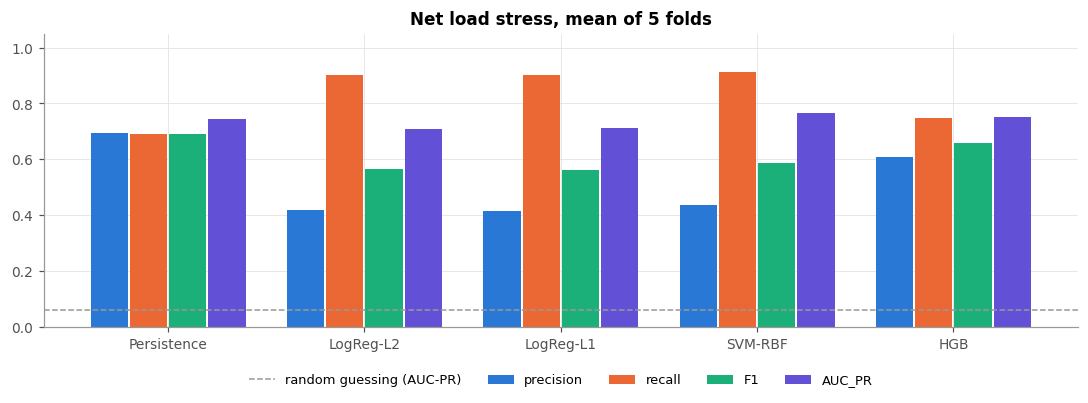

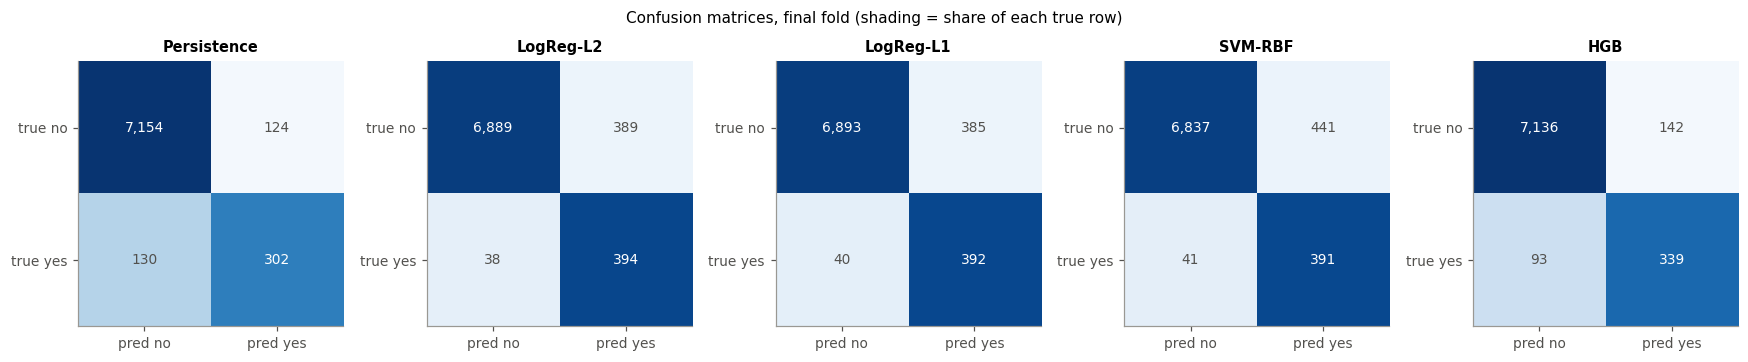

In [45]:
# ===== Chart: scores side by side, and the confusion matrices =====
nlres = cls[cls["label"] == "stress_nl"].set_index("model")
fig, ax = plt.subplots(figsize=(10, 3.8))
xx = np.arange(len(nlres))
for i, (m_, col) in enumerate(zip(["precision", "recall", "F1", "AUC_PR"], [BLUE, ORANGE, AQUA, VIOLET])):
    ax.bar(xx + (i - 1.5) * 0.2, nlres[m_], 0.19, color=col, label=m_)
ax.axhline(nlres["base_rate"].iloc[0], color=GREY, ls="--", lw=1, label="random guessing (AUC-PR)")
ax.set_xticks(xx, nlres.index); ax.set_ylim(0, 1.05)
ax.set_title("Net load stress, mean of 5 folds"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

names = [n for (l, n) in last_cm if l == "stress_nl"]
fig, ax = plt.subplots(1, len(names), figsize=(3.2 * len(names), 3.2))
for a, n in zip(ax, names):
    cm = last_cm[("stress_nl", n)]
    a.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=9,
                   color="white" if cm[i, j] / cm[i].sum() > 0.6 else INK)
    a.set_xticks([0, 1], ["pred no", "pred yes"]); a.set_yticks([0, 1], ["true no", "true yes"])
    a.grid(False); a.set_title(n, fontsize=9.5)
plt.suptitle("Confusion matrices, final fold (shading = share of each true row)", fontsize=10)
plt.tight_layout(); plt.show()

**How to read it.** Compare every AUC-PR with `base_rate` and with Persistence. Then look at the
confusion matrices: `class_weight="balanced"` pushes models toward high recall and many false
alarms, which 10c fixes properly.

**What it shows.** Persistence is strong: AUC-PR 0.746 and F1 0.69 on the net load label. The best
model (RBF SVM) reaches AUC-PR 0.767. Models with class weights catch about 90% of stress hours but
raise far more false alarms. Gradient boosting is the most balanced (precision 0.61, recall 0.75).

### 10c. Choosing the alarm threshold

The default rule flags a stress hour when P(stress) > 0.5. For a grid
operator, missing a real stress hour (false negative) is much worse than a false alarm (false
positive), so 0.5 is rarely the right line.

We use plain logistic regression (no class weights) so the output is a real probability, then lower
the threshold step by step. FPR is the Type I error rate and FNR the Type II error rate. The cost
columns assume a missed stress hour costs 2, 5 or 10 times a false alarm.

In [46]:
# ===== 10c. Choosing the alarm threshold =====
# plain logistic regression (no class weights) so the output is a real probability
tr, te = folds[-1]
lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
lr.fit(dc.loc[tr, X_COLS], dc.loc[tr, "stress_nl"])
prob = lr.predict_proba(dc.loc[te, X_COLS])[:, 1]
yt = dc.loc[te, "stress_nl"].values

rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]:
    tn, fp, fn, tp = confusion_matrix(yt, (prob > t).astype(int)).ravel()
    rows.append({"threshold": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "precision": tp / max(tp + fp, 1), "recall": tp / (tp + fn),
                 "FPR": fp / (fp + tn), "FNR": fn / (fn + tp),
                 "total_error": (fp + fn) / len(yt),
                 **{f"cost_{r}to1": fn * r + fp for r in (2, 5, 10)}})
th = pd.DataFrame(rows)
print(th.round(3).to_string(index=False))
for r in (2, 5, 10):
    best = th.loc[th[f"cost_{r}to1"].idxmin(), "threshold"]
    print(f"if a missed stress hour costs {r}x a false alarm, the best threshold is {best}")

 threshold  TP  FP  FN   TN  precision  recall   FPR   FNR  total_error  cost_2to1  cost_5to1  cost_10to1
      0.50 261  32 171 7246      0.891   0.604 0.004 0.396        0.026        374        887        1742
      0.40 291  54 141 7224      0.843   0.674 0.007 0.326        0.025        336        759        1464
      0.30 317  85 115 7193      0.789   0.734 0.012 0.266        0.026        315        660        1235
      0.20 352 145  80 7133      0.708   0.815 0.020 0.185        0.029        305        545         945
      0.15 366 199  66 7079      0.648   0.847 0.027 0.153        0.034        331        529         859
      0.10 382 293  50 6985      0.566   0.884 0.040 0.116        0.044        393        543         793
      0.05 404 486  28 6792      0.454   0.935 0.067 0.065        0.067        542        626         766
if a missed stress hour costs 2x a false alarm, the best threshold is 0.2
if a missed stress hour costs 5x a false alarm, the best threshold is 0.15
if 

**Chart.** Left: the trade-off as the threshold drops. Right: cost of each threshold relative to the best one; the open circle marks the best threshold for each cost ratio.

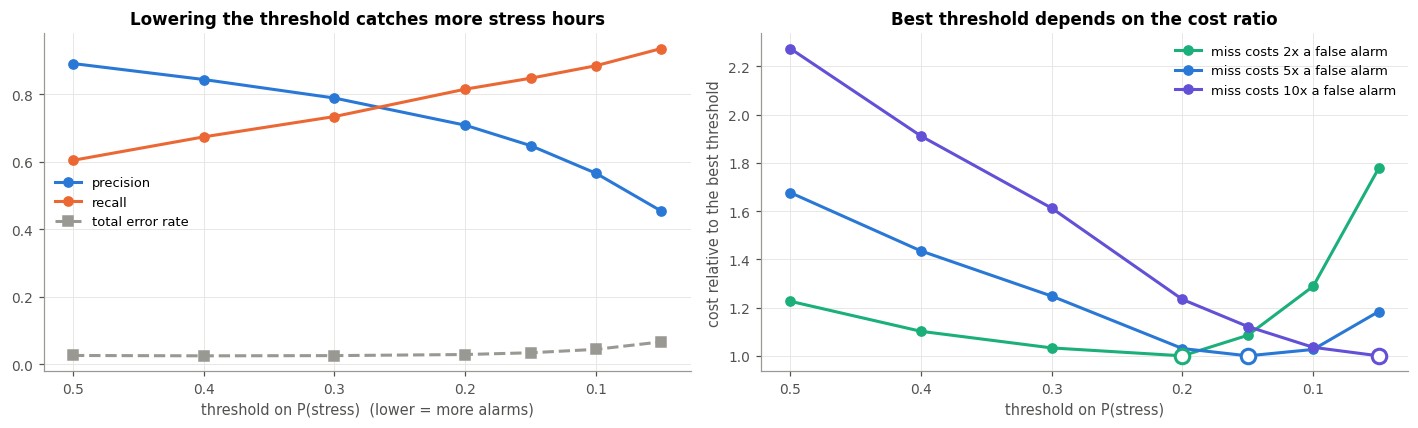

In [47]:
# ===== Chart: the threshold trade-off =====
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(th["threshold"], th["precision"], "o-", color=BLUE, label="precision")
ax[0].plot(th["threshold"], th["recall"], "o-", color=ORANGE, label="recall")
ax[0].plot(th["threshold"], th["total_error"], "s--", color=GREY, label="total error rate")
ax[0].invert_xaxis(); ax[0].set_xlabel("threshold on P(stress)  (lower = more alarms)")
ax[0].set_title("Lowering the threshold catches more stress hours"); ax[0].legend()
for r, col in [(2, AQUA), (5, BLUE), (10, VIOLET)]:
    c = th[f"cost_{r}to1"] / th[f"cost_{r}to1"].min()
    ax[1].plot(th["threshold"], c, "o-", color=col, label=f"miss costs {r}x a false alarm")
    b = th.loc[th[f"cost_{r}to1"].idxmin(), "threshold"]
    ax[1].scatter([b], [1], s=90, facecolor="white", edgecolor=col, zorder=3, lw=2)
ax[1].invert_xaxis(); ax[1].set_xlabel("threshold on P(stress)")
ax[1].set_ylabel("cost relative to the best threshold"); ax[1].set_title("Best threshold depends on the cost ratio")
ax[1].legend(); plt.tight_layout(); plt.show()

**How to read it.** Lowering the threshold trades false negatives for false positives. The total error
rate goes up (most hours are not stress, so a small rise in FPR is many hours) even while the
cost-weighted error goes down. The right threshold depends on the cost ratio, which is an operating
decision, not a statistical one.

**What it shows.** At the default 0.5, logistic regression misses 40% of stress hours. If a miss costs
5x a false alarm, the best threshold is 0.15: recall 85% with 199 false alarms in the final fold.
Note: this threshold is chosen on the test fold, so it is optimistic; the next version picks it on a
held-out slice of the training window.

---
# 11. Unsupervised: are daily load shapes changing?

PCA and K-means, applied to every day from 2019 to 2026. Each day becomes 24
numbers: the load at each hour divided by that day's mean, so we compare **shape, not size**.

K is chosen with the elbow (inertia) and the silhouette score. Season dominates the clusters (summer
days are peaky, mild days are flatter), so we also look at summer days only.

In [48]:
# ===== 11. Unsupervised: clustering daily load shapes =====
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

x = feat[["ts", "demand"]].dropna().copy()
lt = x["ts"].dt.tz_convert("US/Central")
x["date"], x["hr"] = lt.dt.date, lt.dt.hour
P = x.pivot_table(index="date", columns="hr", values="demand", aggfunc="mean")
P = P.interpolate(axis=1, limit_direction="both").dropna()     # fills the one missing DST hour
P = P[P.notna().all(axis=1) & (P.count(axis=1) == 24)]
S = P.div(P.mean(axis=1), axis=0)                               # shape only: each day / its own mean
year = pd.to_datetime(S.index).year
month = pd.to_datetime(S.index).month
print(f"days: {len(S):,}   hours per day: {S.shape[1]}")

# how many clusters? inertia (elbow) and silhouette
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(S)
    print(f"K={k}  inertia {km.inertia_:7.2f}  silhouette {silhouette_score(S, km.labels_, sample_size=2000, random_state=0):.3f}")

days: 2,818   hours per day: 24
K=2  inertia  132.46  silhouette 0.523
K=3  inertia   82.12  silhouette 0.450
K=4  inertia   66.66  silhouette 0.365
K=5  inertia   57.70  silhouette 0.317
K=6  inertia   51.55  silhouette 0.257
K=7  inertia   47.64  silhouette 0.252


Pick K where silhouette is still high and the inertia curve bends, then set `K` in the next cell.

Silhouette prefers K = 2, but that only splits summer from the rest of the year. K = 4 separates the
shapes we care about. The summer-only table is the result.

cluster profile: mean min/max ratio and typical months
  cluster 0: ratio 0.632   days  1141   top months [8, 7, 6]
  cluster 1: ratio 0.723   days   761   top months [4, 3, 5]
  cluster 2: ratio 0.795   days   322   top months [1, 2, 12]
  cluster 3: ratio 0.802   days   594   top months [1, 12, 2]

share of days in each cluster, by year (full years only), %
cluster     0     1     2     3
year                           
2019     42.2  21.6  14.8  21.4
2020     44.5  23.2  11.2  21.0
2021     39.5  27.4   9.0  24.1
2022     45.5  21.4  17.0  16.2
2023     39.5  25.5  11.0  24.1
2024     36.3  30.9   7.9  24.9
2025     37.5  33.4  11.0  18.1

same, summer days only (Jun to Sep), removes the season effect, %
cluster     0     1    3
year                    
2019     91.8   8.2  0.0
2020     87.7  11.5  0.8
2021     87.7  12.3  0.0
2022     94.3   5.7  0.0
2023     92.6   7.4  0.0
2024     77.0  23.0  0.0
2025     77.9  22.1  0.0

PCA: first two components explain 94.2% of shape variance

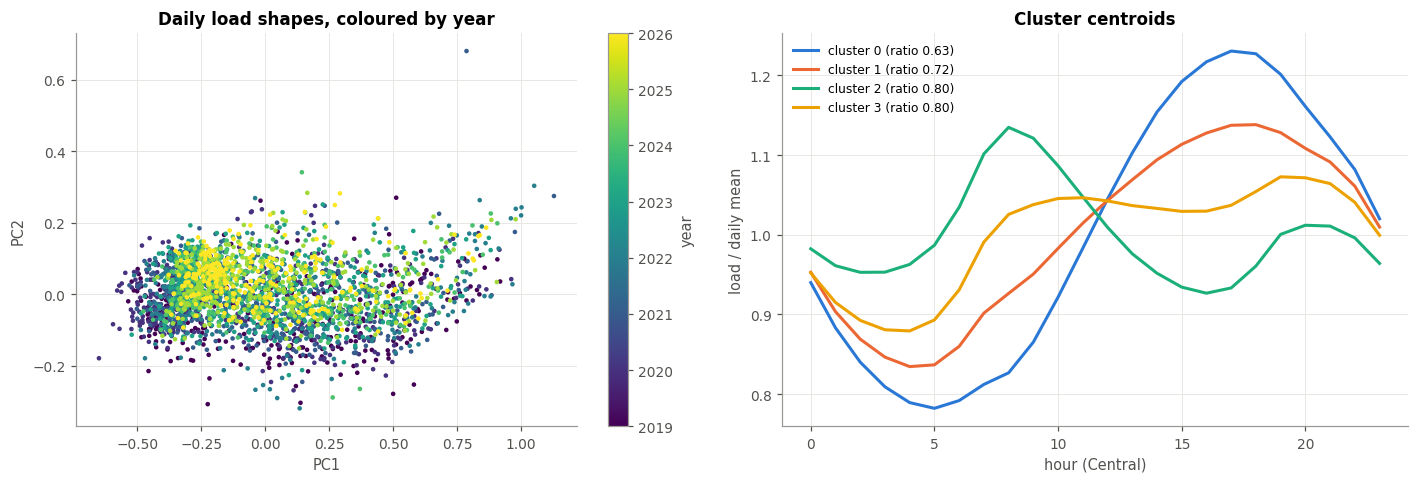

In [49]:
K = 4                        # set from the elbow and silhouette above
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(S)
lab = pd.Series(km.labels_, index=S.index)
flat = S.min(axis=1) / S.max(axis=1)
order = flat.groupby(lab).mean().sort_values().index            # cluster 0 = peakiest, K-1 = flattest
lab = lab.map({c: i for i, c in enumerate(order)})

print("cluster profile: mean min/max ratio and typical months")
for c in range(K):
    mm = pd.Series(month[lab.values == c]).value_counts().index[:3].tolist()
    print(f"  cluster {c}: ratio {flat[lab == c].mean():.3f}   days {int((lab == c).sum()):>5}   top months {mm}")

full = year <= 2025
print("\nshare of days in each cluster, by year (full years only), %")
print((pd.crosstab(pd.Series(year[full], name="year"), pd.Series(lab.values[full], name="cluster"), normalize="index") * 100).round(1).to_string())
summer = full & np.isin(month, [6, 7, 8, 9])
print("\nsame, summer days only (Jun to Sep), removes the season effect, %")
print((pd.crosstab(pd.Series(year[summer], name="year"), pd.Series(lab.values[summer], name="cluster"), normalize="index") * 100).round(1).to_string())

pca = PCA(n_components=2).fit(S)
Z = pca.transform(S)
print(f"\nPCA: first two components explain {pca.explained_variance_ratio_.sum() * 100:.1f}% of shape variance")
print("mean PC1 score by year:", pd.Series(Z[:, 0]).groupby(year).mean().round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sc_ = ax[0].scatter(Z[:, 0], Z[:, 1], c=year, s=4, cmap="viridis")
plt.colorbar(sc_, ax=ax[0], label="year")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].set_title("Daily load shapes, coloured by year")
for c in range(K):
    ax[1].plot(range(24), S[lab == c].mean(), label=f"cluster {c} (ratio {flat[lab == c].mean():.2f})")
ax[1].set_xlabel("hour (Central)"); ax[1].set_ylabel("load / daily mean")
ax[1].set_title("Cluster centroids"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**How to read it.** Clusters are numbered from peakiest (0) to flattest. If the share of days in the
flatter clusters grows year by year, especially within summer only, that is independent
unsupervised evidence for F1. The mean PC1 score drifting by year says the same thing in one number.

**What it shows.** In summer, the share of days in the flatter cluster rose from 8% (2019) to 22-23%
(2024 to 2025). Summer days are getting less peaky, which fits a growing always-on load.

---
# 12. Conclusions (FIN)

**Q1. How well can ERCOT load be predicted 24 hours ahead from public data?** Demand: about 3% error,
with Ridge on weather, calendar and lagged load. That is about one point behind ERCOT's own forecast,
which uses private scheduling data. Net load: about 12%, because wind and solar errors are much larger.

**Q2. Can stress hours be flagged 24 hours ahead?** Yes, but "same as yesterday" already does most of
the work. Models add a little (AUC-PR 0.767 vs 0.746) and let an operator trade false alarms for
missed stress hours with a chosen cost ratio.

**Q3. Has predictability changed as the load mix shifted?** Not for demand as a whole: error is flat or
improving. What changed is why the model works. Texas load is measurably less weather-driven per MW
(F5, significant), the change is concentrated in Far West Texas (F6) and a model now has to know the
rising always-on floor to stay accurate (F7). For net load, the forecasting burden moved to the supply
side as solar grew (F4).

| Hypothesis | Verdict | Evidence |
|---|---|---|
| H1. The floor rises faster than the peak | Supported | F1, F2, F10 |
| H2. Texas load got harder to predict | Rejected for demand; net load harder only because solar grew | F3, F4 |
| H3. Load is less weather-driven per MW | Supported | F5, F6, F7, 9g |
| H4. Stress hours beat "same as yesterday" | Partly | F9 |

**Limitations.** Weather is actual, not forecast, so our errors are a lower bound. ERCOT does not publish
load by customer type, so the Far West pattern is consistent with data center and crypto load but does
not prove it (oil and gas activity is also concentrated there). The large-load wave is recent, so the
late era is short. ERCOT's forecast uses private data, so the benchmark measures the public-data gap,
not a fair contest.

**Next.** Run the same analysis on other US grids (PJM, MISO, CAISO, SPP) to see whether Texas stands
out, and choose the stress threshold on held-out data.